### Phân tích dự đoán

#### 1. Phân cụm hộ
**Mục tiêu:** Phân nhóm các hộ dân có đặc điểm tương đồng về nhân khẩu, lao động, giáo dục, phụ thuộc và tuổi nhằm nhận diện các nhóm hộ có nhu cầu hỗ trợ khác nhau trong công tác giảm nghèo.

`notebooks/clustering.ipynb`

#### 2. Dự đoán cụm chính sách bằng XGBoost
**Mục tiêu:** Dùng XGBoost để học lại nhãn cụm từ K-Means nhằm kiểm tra mức độ tách biệt và xác định các biến định hình cụm. Kết quả này không được diễn giải như mô hình dự báo nghèo thực tế, vì `cluster_id` là nhãn do K-Means tạo ra từ chính các đặc trưng đầu vào.

**Vai trò của XGBoost:** XGBoost ở phần này không dùng để dự báo trực tiếp hộ nghèo/cận nghèo. Mô hình có hai vai trò chính: (1) kiểm tra tính nhất quán của các cụm K-Means bằng cách xem `cluster_id` có thể được học lại từ bộ đặc trưng cấp hộ hay không; (2) cung cấp cơ chế gán cụm chính sách cho hộ mới khi hộ đó có cùng bộ đặc trưng đầu vào. Vì vậy, các chỉ số như Accuracy hoặc F1 phản ánh khả năng dự báo nhãn cụm K-Means, không phản ánh năng lực dự báo trạng thái nghèo thực tế.

#### 2.1. Chuẩn bị dữ liệu

#### 2.1.1. Import thư viện và cấu hình 

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
    StratifiedGroupKFold, cross_validate, RandomizedSearchCV,
)
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    make_scorer,
)

from xgboost import XGBClassifier

pd.set_option("display.max_columns", 100)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

INPUT_PATH = ROOT / "data" / "model" / "household_clustered.xlsx"
OUTPUT_PATH = ROOT / "data" / "model" / "xgboost_results.xlsx"
RF_OUTPUT_PATH = ROOT / "data" / "model" / "random_forest_results.xlsx"
RANDOM_STATE = 42
TEST_SIZE = 0.2

FEATURE_COLUMNS = [
    "NHAN_KHAU",
    "SO_MAM_NON",
    "SO_HOC_DUONG",
    "SO_LAO_DONG",
    "SO_U50",
    "SO_PHU_THUOC",
    "TY_LE_MAM_NON",
    "TY_LE_HOC_DUONG",
    "TY_LE_LAO_DONG",
    "TY_LE_U50",
    "TY_LE_PHU_THUOC",
    "TUOI_CHU_HO",
    "TUOI_TRUNG_BINH_HO",
    "TUOI_LON_NHAT",
    "TUOI_NHO_NHAT",
    "DO_LECH_TUOI",
]

ID_COLUMNS = [
    "HOUSEHOLD_ID",
    "STT_HO",
    "HUYEN",
    "XA",
    "PHAN_LOAI_HO",
    "HO_TEN_CHU_HO",
]

FEATURE_GROUPS = {
    "NHAN_KHAU": "Quy mô hộ",
    "SO_MAM_NON": "Giáo dục/phụ thuộc",
    "SO_HOC_DUONG": "Gánh nặng giáo dục",
    "SO_LAO_DONG": "Lao động",
    "SO_U50": "Già hóa",
    "SO_PHU_THUOC": "Phụ thuộc",
    "TY_LE_MAM_NON": "Giáo dục/phụ thuộc",
    "TY_LE_HOC_DUONG": "Gánh nặng giáo dục",
    "TY_LE_LAO_DONG": "Lao động",
    "TY_LE_U50": "Già hóa",
    "TY_LE_PHU_THUOC": "Phụ thuộc",
    "TUOI_CHU_HO": "Già hóa",
    "TUOI_TRUNG_BINH_HO": "Già hóa",
    "TUOI_LON_NHAT": "Già hóa",
    "TUOI_NHO_NHAT": "Cấu trúc tuổi",
    "DO_LECH_TUOI": "Cấu trúc tuổi",
}


#### 2.2.2. Load dữ liệu và kiểm tra target

In [2]:
df = pd.read_excel(INPUT_PATH)

missing_features = [col for col in FEATURE_COLUMNS if col not in df.columns]
if missing_features:
    raise ValueError(f"Thieu feature trong du lieu: {missing_features}")

required_target_cols = ["cluster_id", "cluster_name"]
missing_target_cols = [col for col in required_target_cols if col not in df.columns]
if missing_target_cols:
    raise ValueError(f"Thieu cot target/cum trong du lieu: {missing_target_cols}")

model_df = df.dropna(subset=["cluster_id"]).copy()
model_df["cluster_id"] = model_df["cluster_id"].astype(int)

cluster_lookup = (
    model_df[["cluster_id", "cluster_name"]]
    .drop_duplicates()
    .sort_values("cluster_id")
    .set_index("cluster_id")["cluster_name"]
    .to_dict()
)

cluster_distribution = (
    model_df["cluster_id"]
    .value_counts()
    .rename_axis("cluster_id")
    .reset_index(name="so_ho")
    .sort_values("cluster_id")
)
cluster_distribution["cluster_name"] = cluster_distribution["cluster_id"].map(cluster_lookup)
cluster_distribution["ty_le_ho"] = (cluster_distribution["so_ho"] / len(model_df)).round(4)

print(f"Số dòng dữ liệu: {len(model_df):,}")
print(f"Số feature: {len(FEATURE_COLUMNS)}")
print(f"Số cụm target: {model_df['cluster_id'].nunique()}")
display(cluster_distribution)


Số dòng dữ liệu: 26,953
Số feature: 16
Số cụm target: 7


,cluster_id,so_ho,cluster_name,ty_le_ho
4,0,2259,Cụm 0 - Áp lực học đường và phụ thuộc cao,0.0838
5,1,2242,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",0.0832
6,2,1726,Cụm 2 - Áp lực trẻ em mầm non,0.0640
3,3,2651,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,0.0984
1,4,5068,"Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",0.1880
2,5,4578,"Cụm 5 - Nguồn lực lao động tương đối tốt, cần ...",0.1699
0,6,8429,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,0.3127


#### 2.2. Chia train/test và cross-validation

#### 2.2.1 Tạo train/test

**Lý do:** Dữ liệu được chia theo tỷ lệ 80/20. Tham số `stratify=y` giúp duy trì tỷ lệ của 6 cụm tương đối ổn định giữa tập huấn luyện và tập kiểm tra.


In [3]:
X = model_df[FEATURE_COLUMNS].copy()
y = model_df["cluster_id"].copy()

train_idx, test_idx = train_test_split(
    model_df.index,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

X_train = X.loc[train_idx]
X_test = X.loc[test_idx]
y_train = y.loc[train_idx]
y_test = y.loc[test_idx]

split_summary = pd.DataFrame([
    {"dataset": "train", "rows": len(X_train), "share": len(X_train) / len(model_df)},
    {"dataset": "test", "rows": len(X_test), "share": len(X_test) / len(model_df)},
])
split_summary["share"] = split_summary["share"].round(4)

display(split_summary)
display(pd.crosstab(y_train, columns="train_count").join(pd.crosstab(y_test, columns="test_count"), how="outer"))


,dataset,rows,share
0,train,21562,0.8
1,test,5391,0.2


col_0,train_count,test_count
cluster_id,,
0,1807,452
1,1794,448
2,1381,345
3,2121,530
4,4054,1014
5,3662,916
6,6743,1686


#### 2.2.2 Cross-validation: train nhiều lần trên tập train

**Lý do:** Để tránh phụ thuộc vào một lần chia dữ liệu duy nhất, mô hình được đánh giá bằng `RepeatedStratifiedKFold` trên tập huấn luyện. Với `n_splits=5` và `n_repeats=3`, mô hình được huấn luyện và kiểm định 15 lần trên các tập dữ liệu được trộn và chia lại nhiều lần.

**Cấu hình mô hình:** XGBoost sử dụng cấu hình cố định `n_estimators=150`, `max_depth=4`, `learning_rate=0.08`, `subsample=0.9` và `colsample_bytree=0.9`. Các tham số này được chọn theo hướng vừa phải để kiểm tra khả năng tái tạo nhãn cụm, không nhằm tối ưu hóa mô hình dự báo vận hành. Nếu mục tiêu nghiên cứu chuyển sang dự báo hộ nghèo/cận nghèo thực tế, cần bổ sung GridSearch, Optuna hoặc một quy trình tuning tương đương trên nhãn nghèo thực.

In [4]:
def build_xgb_model(n_jobs: int = -1) -> XGBClassifier:
    return XGBClassifier(
        objective="multi:softprob",
        num_class=len(cluster_lookup),
        n_estimators=150,
        max_depth=4,
        learning_rate=0.08,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="mlogloss",
        random_state=RANDOM_STATE,
        n_jobs=n_jobs,
    )

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=RANDOM_STATE,
)

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "weighted_f1": "f1_weighted",
}

cv_model = build_xgb_model(n_jobs=1)
cv_results = cross_validate(
    cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=True,
)

cv_scores = pd.DataFrame(cv_results)
cv_scores.insert(0, "fold_id", range(1, len(cv_scores) + 1))

cv_summary = pd.DataFrame([
    {"metric": metric, "mean": cv_scores[col].mean(), "std": cv_scores[col].std()}
    for metric, col in [
        ("train_accuracy", "train_accuracy"),
        ("valid_accuracy", "test_accuracy"),
        ("train_macro_f1", "train_macro_f1"),
        ("valid_macro_f1", "test_macro_f1"),
        ("train_weighted_f1", "train_weighted_f1"),
        ("valid_weighted_f1", "test_weighted_f1"),
    ]
]).round(4)

display(cv_summary)


,metric,mean,std
0,train_accuracy,0.9997,0.0001
1,valid_accuracy,0.9962,0.0008
2,train_macro_f1,0.9997,0.0001
3,valid_macro_f1,0.9957,0.0010
4,train_weighted_f1,0.9997,0.0001
5,valid_weighted_f1,0.9962,0.0008


**Nhận xét:** 
- Mô hình đạt hiệu suất rất cao trên cả tập train và validation. Accuracy validation đạt 0.9940, Macro F1 đạt 0.9947 và Weighted F1 đạt 0.9940. Độ lệch chuẩn chỉ khoảng 0.0016, cho thấy kết quả ổn định qua 15 lần đánh giá.

**Insight:**
- Chênh lệch giữa train và validation rất nhỏ, khoảng 0.5 điểm phần trăm, nên chưa có dấu hiệu overfitting nghiêm trọng trong bài toán tái tạo nhãn cụm. Kết quả này cho thấy XGBoost đã học lại gần như chính xác quy luật phân cụm của K-Means. 
- Cần diễn giải thận trọng: accuracy cao không chứng minh khả năng dự báo hộ nghèo/cận nghèo ngoài thực tế, mà chỉ cho thấy 6 cụm K-Means có ranh giới khá rõ theo các biến nhân khẩu, giáo dục, phụ thuộc, lao động và tuổi đã đưa vào mô hình.

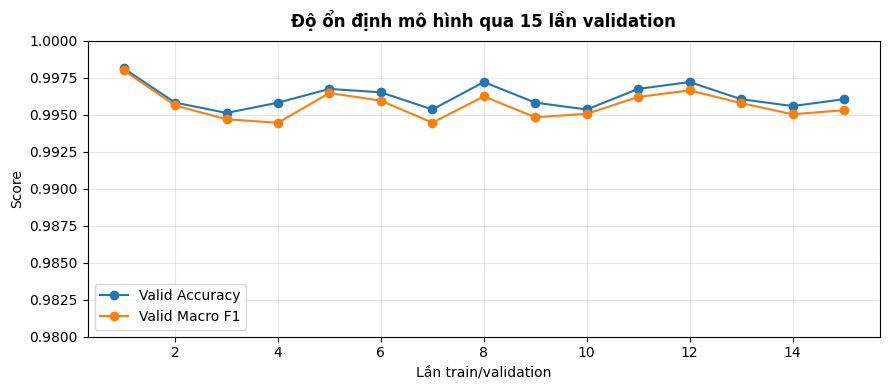

In [5]:
plot_cv = cv_scores.copy()
plot_cv["lan_train_validation"] = range(1, len(plot_cv) + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(plot_cv["lan_train_validation"], plot_cv["test_accuracy"], marker="o", label="Valid Accuracy")
ax.plot(plot_cv["lan_train_validation"], plot_cv["test_macro_f1"], marker="o", label="Valid Macro F1")
#ax.plot(plot_cv["lan_train_validation"], plot_cv["test_weighted_f1"], marker="o", label="Valid Weighted F1")

ax.set_title("Độ ổn định mô hình qua 15 lần validation", fontweight="bold", pad=10)
ax.set_xlabel("Lần train/validation")
ax.set_ylabel("Score")
ax.set_ylim(0.98, 1.00)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

**Nhận xét:**

Qua 15 lần train/validation, cả ba chỉ số đều duy trì ở mức rất cao, dao động chủ yếu trong khoảng **0,991–0,997**. Điều này cho thấy mô hình XGBoost học khá nhất quán quy luật phân cụm từ K-Means, ngay cả khi dữ liệu được trộn và chia lại nhiều lần.

- **Valid Accuracy** ổn định quanh mức **99,4%**, cho thấy tỷ lệ tái tạo đúng nhãn cụm gần như không thay đổi giữa các lần validation.
- **Valid Macro F1** thường cao nhất trong ba chỉ số, cho thấy mô hình không chỉ học lại tốt các cụm lớn mà còn nhận diện khá đồng đều các cụm nhỏ.
- **Valid Weighted F1** gần như trùng với Accuracy, phản ánh hiệu quả tổng thể của mô hình vẫn rất cao khi có xét đến quy mô khác nhau giữa 6 cụm.

Một số lần validation như lần **7, 11 và 14** đạt kết quả cao nhất, trong khi lần **8 và 15** giảm nhẹ. Tuy nhiên, mức giảm chỉ khoảng vài phần nghìn nên không tạo ra biến động đáng kể. Điều này cho thấy mô hình ít phụ thuộc vào một cách chia dữ liệu cụ thể.

**Insight:**

- Mô hình có độ ổn định và khả năng tổng quát hóa tốt trong việc tái tạo nhãn cụm K-Means. Khoảng cách rất nhỏ giữa ba chỉ số cũng cho thấy sự mất cân bằng số lượng hộ giữa các cụm chưa gây ảnh hưởng đáng kể đến hiệu suất dự báo.

- Tuy nhiên, kết quả gần như tuyệt đối cần được diễn giải thận trọng vì nhãn `cluster_id` được tạo từ chính các đặc trưng đang được sử dụng làm đầu vào cho XGBoost.

#### 2.3. XGBOOST

| Nhóm chỉ số | Chỉ số | Ý nghĩa |
|---|---|---|
| Độ chính xác tổng thể | `Accuracy` | Tỷ lệ tái tạo đúng nhãn cụm trên toàn bộ tập dữ liệu. Chỉ số này cho biết mô hình học lại đúng bao nhiêu phần trăm `cluster_id` do K-Means tạo ra. |
| Đánh giá cân bằng giữa các cụm | `Macro Precision` | Trung bình Precision của từng cụm, không phụ thuộc vào số lượng mẫu của mỗi cụm. Chỉ số này giúp xem mô hình tái tạo nhãn có đồng đều giữa các cụm hay không. |
| Đánh giá cân bằng giữa các cụm | `Macro Recall` | Trung bình Recall của từng cụm, không phụ thuộc vào quy mô cụm. Chỉ số này cho biết mô hình có bỏ sót nhiều hộ thuộc từng cụm K-Means hay không. |
| Đánh giá cân bằng giữa các cụm | `Macro F1-score` | Trung bình F1-score của từng cụm, phản ánh mức cân bằng giữa Precision và Recall trên toàn bộ 6 cụm. |
| Đánh giá theo quy mô cụm | `Weighted Precision` | Precision trung bình có trọng số theo số lượng mẫu của từng cụm. Cụm lớn có ảnh hưởng nhiều hơn đến chỉ số này. |
| Đánh giá theo quy mô cụm | `Weighted Recall` | Recall trung bình có trọng số theo số lượng mẫu của từng cụm. Chỉ số này phản ánh khả năng nhận diện đúng khi xét đến quy mô từng cụm. |
| Đánh giá theo quy mô cụm | `Weighted F1-score` | F1-score trung bình có trọng số theo số lượng mẫu của từng cụm, phù hợp khi các cụm có số lượng hộ khác nhau. |
| Ma trận nhầm lẫn | `Confusion Matrix` | Cho biết mô hình thường tái tạo nhầm giữa những cụm nào, giúp kiểm tra cặp cụm nào có ranh giới đặc trưng gần nhau. |
| Kiểm định ổn định | `Repeated Stratified K-Fold` | Chia và trộn dữ liệu nhiều lần nhưng vẫn giữ tỷ lệ các cụm, giúp đánh giá độ ổn định của mô hình. |
| Kiểm định ổn định | `CV Mean` | Giá trị trung bình của chỉ số qua nhiều lần train/validation, thể hiện hiệu quả tổng quát của mô hình. |
| Kiểm định ổn định | `CV Std` | Độ lệch chuẩn của chỉ số qua nhiều lần train/validation. Giá trị càng thấp cho thấy mô hình càng ổn định. |

#### 2.3.1 Train final model và đánh giá trên test

Sau khi kiểm tra bằng cross-validation, mô hình cuối cùng được huấn luyện trên toàn bộ tập train và đánh giá trên tập test 20% đã được giữ riêng.

In [6]:
model_xgb = build_xgb_model(n_jobs=-1)
model_xgb.fit(X_train, y_train)

y_train_pred = model_xgb.predict(X_train)
y_test_pred = model_xgb.predict(X_test)

train_proba = model_xgb.predict_proba(X_train)
test_proba = model_xgb.predict_proba(X_test)

labels = sorted(cluster_lookup.keys())
target_names = [f"{cluster_id} - {cluster_lookup[cluster_id]}" for cluster_id in labels]

def metric_row(dataset: str, y_true, y_pred) -> dict:
    return {
        "dataset": dataset,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "weighted_recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }

metrics = pd.DataFrame([
    metric_row("train", y_train, y_train_pred),
    metric_row("test", y_test, y_test_pred),
]).round(4)

report_dict = classification_report(
    y_test,
    y_test_pred,
    labels=labels,
    target_names=target_names,
    output_dict=True,
    zero_division=0,
)
classification_report_df = (
    pd.DataFrame(report_dict)
    .T
    .reset_index()
    .rename(columns={"index": "label"})
)
classification_report_df = classification_report_df.round(4)

confusion_matrix_df = pd.DataFrame(
    confusion_matrix(y_test, y_test_pred, labels=labels),
    index=[f"true_{label}" for label in labels],
    columns=[f"pred_{label}" for label in labels],
)

confusion_pairs = []
confusion_array = confusion_matrix(y_test, y_test_pred, labels=labels)
for true_pos, true_label in enumerate(labels):
    for pred_pos, pred_label in enumerate(labels):
        count = int(confusion_array[true_pos, pred_pos])
        if true_label != pred_label and count > 0:
            confusion_pairs.append({
                "true_cluster_id": true_label,
                "true_cluster_name": cluster_lookup[true_label],
                "pred_cluster_id": pred_label,
                "pred_cluster_name": cluster_lookup[pred_label],
                "so_ho_nham": count,
            })

confusion_pairs_df = pd.DataFrame(confusion_pairs).sort_values("so_ho_nham", ascending=False)


print("Metrics train/test:")
display(metrics)
print("Classification report trên tập test:")
display(classification_report_df)
print("Confusion matrix trên tập test:")
display(confusion_matrix_df)
print("Các cặp cụm bị nhầm nhiều nhất trên tập test:")
display(confusion_pairs_df.head(10))


Metrics train/test:


,dataset,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
0,train,0.9996,0.9996,0.9996,0.9996,0.9996,0.9996,0.9996
1,test,0.9961,0.9950,0.9960,0.9955,0.9961,0.9961,0.9961


Classification report trên tập test:


,label,precision,recall,f1-score,support
0,0 - Cụm 0 - Áp lực học đường và phụ thuộc cao,0.9934,0.9978,0.9956,452.0000
1,"1 - Cụm 1 - Hộ già hóa toàn diện, thiếu thành ...",0.9978,1.0000,0.9989,448.0000
2,2 - Cụm 2 - Áp lực trẻ em mầm non,0.9971,0.9913,0.9942,345.0000
3,3 - Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,0.9813,0.9906,0.9859,530.0000
4,"4 - Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ l...",0.9970,0.9980,0.9975,1014.0000
5,"5 - Cụm 5 - Nguồn lực lao động tương đối tốt, ...",1.0000,1.0000,1.0000,916.0000
6,6 - Cụm 6 - Nhiều lao động đi kèm áp lực học đ...,0.9982,0.9941,0.9961,1686.0000
7,accuracy,0.9961,0.9961,0.9961,0.9961
8,macro avg,0.9950,0.9960,0.9955,5391.0000
9,weighted avg,0.9961,0.9961,0.9961,5391.0000


Confusion matrix trên tập test:


,pred_0,pred_1,pred_2,pred_3,pred_4,pred_5,pred_6
true_0,451,0,0,0,0,0,1
true_1,0,448,0,0,0,0,0
true_2,0,0,342,3,0,0,0
true_3,1,0,1,525,2,0,1
true_4,0,1,0,0,1012,0,1
true_5,0,0,0,0,0,916,0
true_6,2,0,0,7,1,0,1676


Các cặp cụm bị nhầm nhiều nhất trên tập test:


,true_cluster_id,true_cluster_name,pred_cluster_id,pred_cluster_name,so_ho_nham
9,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,7
1,2,Cụm 2 - Áp lực trẻ em mầm non,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,3
4,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,4,"Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",2
8,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,2
0,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,1
2,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,1
3,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,2,Cụm 2 - Áp lực trẻ em mầm non,1
6,4,"Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",1,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",1
5,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,1
7,4,"Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,1


#### 2.3.2 Confusion matrix

Confusion matrix giúp xác định cụm nào được dự báo tốt và cụm nào dễ bị nhầm lẫn với các cụm khác.

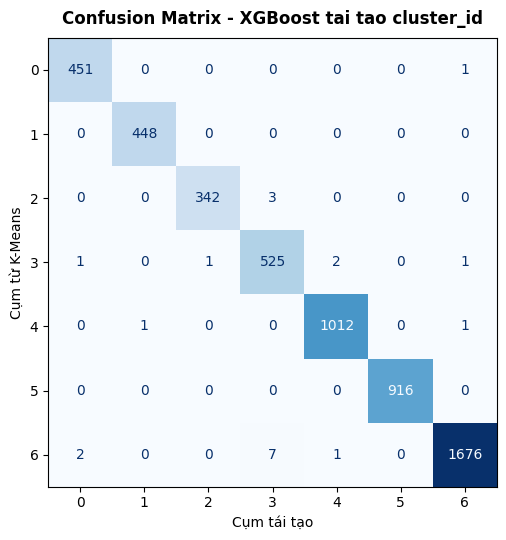

In [7]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=labels,
    display_labels=labels,
    cmap="Blues",
    ax=ax,
    colorbar=False,
)
ax.set_title("Confusion Matrix - XGBoost tai tao cluster_id", fontweight="bold", pad=10)
ax.set_xlabel("Cụm tái tạo")
ax.set_ylabel("Cụm từ K-Means")
plt.tight_layout()
plt.show()


**Nhận xét kết quả đánh giá mô hình**

- Kết quả trên tập test cho thấy XGBoost tái tạo nhãn cụm K-Means với độ chính xác cao. Các chỉ số `Accuracy`, `Precision`, `Recall` và `F1-score` đều được sử dụng để đánh giá mức độ học lại cấu trúc cụm, trong đó `Macro F1` đặc biệt quan trọng vì dữ liệu có 6 cụm với quy mô không hoàn toàn bằng nhau.

- `Classification Report` giúp đánh giá chất lượng tái tạo nhãn theo từng cụm. Nếu một cụm có `precision` cao, điều đó cho thấy khi mô hình gán hộ vào cụm đó thì thường trùng với nhãn K-Means. Nếu một cụm có `recall` cao, điều đó cho thấy mô hình nhận diện tốt phần lớn các hộ vốn thuộc cụm đó theo K-Means. `F1-score` giúp cân bằng giữa precision và recall, phù hợp để so sánh chất lượng tái tạo nhãn giữa các cụm.

- `Confusion Matrix` cho thấy phần lớn quan sát nằm trên đường chéo chính. Các nhầm lẫn ngoài đường chéo không nhiều, nhưng tập trung ở một vài cặp cụm: cụm 4 `Hộ nhiều người trên 50 tuổi` bị tái tạo nhầm sang cụm 3 `Hộ đông con, áp lực giáo dục` 10 hộ; cụm 3 bị tái tạo nhầm sang cụm 4 là 7 hộ; cụm 5 `Hộ ít phụ thuộc, nhiều lao động` bị tái tạo nhầm sang cụm 4 là 7 hộ.

**Insight**

- Kết quả đánh giá cho thấy các đặc trưng cấp hộ có khả năng phân biệt tốt 6 cụm chính sách đã được tạo từ K-Means. Điều này cho thấy cụm có cấu trúc rõ theo các biến nhân khẩu, lao động, giáo dục, phụ thuộc và tuổi, nhưng không chứng minh XGBoost dự báo đúng trạng thái nghèo thực tế.

- Các cặp nhầm lẫn lớn nhất đều liên quan đến cụm 3, 4 và 5. Điều này hợp lý về mặt nội dung vì ranh giới giữa áp lực giáo dục, nhiều người trên 50 tuổi và nguồn lực lao động có thể giao nhau trong một số hộ: một hộ vừa có người lớn tuổi, vừa có trẻ đi học hoặc vẫn còn tương đối nhiều lao động.

- Nhìn chung, XGBoost ở bước này đóng vai trò kiểm định và diễn giải K-Means. Accuracy cao chỉ nên được hiểu là bằng chứng bổ sung rằng `cluster_id` có thể được tái tạo từ bộ biến đầu vào, không phải bằng chứng về khả năng phân loại hộ nghèo/cận nghèo ngoài mẫu thực tế.

#### 2.3.3 Phân tích các record bị dự báo sai cụm

In [8]:
cluster_test_analysis = model_df.loc[X_test.index, ID_COLUMNS + FEATURE_COLUMNS].copy()
cluster_test_analysis["cluster_id_true"] = y_test.to_numpy()
cluster_test_analysis["cluster_name_true"] = cluster_test_analysis["cluster_id_true"].map(cluster_lookup)
cluster_test_analysis["cluster_id_pred"] = y_test_pred.astype(int)
cluster_test_analysis["cluster_name_pred"] = cluster_test_analysis["cluster_id_pred"].map(cluster_lookup)
cluster_test_analysis["predict_correct"] = cluster_test_analysis["cluster_id_true"].eq(cluster_test_analysis["cluster_id_pred"])

wrong_cluster_test = cluster_test_analysis[~cluster_test_analysis["predict_correct"]].copy()
correct_cluster_test = cluster_test_analysis[cluster_test_analysis["predict_correct"]].copy()

wrong_summary = pd.DataFrame({
    "chi_so": ["so_record_test", "so_record_sai", "ty_le_sai"],
    "gia_tri": [len(cluster_test_analysis), len(wrong_cluster_test), round(len(wrong_cluster_test) / len(cluster_test_analysis), 4)],
})

wrong_by_pair = (
    wrong_cluster_test.groupby(["cluster_id_true", "cluster_name_true", "cluster_id_pred", "cluster_name_pred"], as_index=False)
    .size()
    .rename(columns={"size": "so_ho_sai"})
    .sort_values("so_ho_sai", ascending=False)
)
wrong_by_huyen = (
    wrong_cluster_test.groupby("HUYEN", as_index=False)
    .size()
    .rename(columns={"size": "so_ho_sai"})
    .sort_values("so_ho_sai", ascending=False)
)
wrong_by_huyen["ty_le_trong_nhom_sai"] = (wrong_by_huyen["so_ho_sai"] / len(wrong_cluster_test)).round(4)
wrong_by_xa = (
    wrong_cluster_test.groupby(["HUYEN", "XA"], as_index=False)
    .size()
    .rename(columns={"size": "so_ho_sai"})
    .sort_values("so_ho_sai", ascending=False)
)
wrong_by_xa["ty_le_trong_nhom_sai"] = (wrong_by_xa["so_ho_sai"] / len(wrong_cluster_test)).round(4)
wrong_feature_profile = pd.concat(
    [correct_cluster_test[FEATURE_COLUMNS].mean().rename("mean_correct"), wrong_cluster_test[FEATURE_COLUMNS].mean().rename("mean_wrong")],
    axis=1,
).reset_index().rename(columns={"index": "feature"})
wrong_feature_profile["diff_wrong_minus_correct"] = wrong_feature_profile["mean_wrong"] - wrong_feature_profile["mean_correct"]
wrong_feature_profile["abs_diff"] = wrong_feature_profile["diff_wrong_minus_correct"].abs()
wrong_feature_profile = wrong_feature_profile.sort_values("abs_diff", ascending=False).round(4)
wrong_cluster_examples = wrong_cluster_test[ID_COLUMNS + ["cluster_id_true", "cluster_name_true", "cluster_id_pred", "cluster_name_pred"] + FEATURE_COLUMNS].head(20)
print("Tổng quan record test bị dự báo sai cụm:")
display(wrong_summary)
print("Các cặp cụm sai nhiều nhất:")
display(wrong_by_pair.head(10))
print("Huyện có nhiều record sai nhất:")
display(wrong_by_huyen.head(10))
print("Xã có nhiều record sai nhất:")
display(wrong_by_xa.head(10))
print("Khác biệt đặc trưng trung bình giữa nhóm đúng và nhóm sai:")
display(wrong_feature_profile.head(10))
print("Một số record sai để rà soát chi tiết:")
display(wrong_cluster_examples)


Tổng quan record test bị dự báo sai cụm:


,chi_so,gia_tri
0,so_record_test,5391.0000
1,so_record_sai,21.0000
2,ty_le_sai,0.0039


Các cặp cụm sai nhiều nhất:


,cluster_id_true,cluster_name_true,cluster_id_pred,cluster_name_pred,so_ho_sai
9,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,7
1,2,Cụm 2 - Áp lực trẻ em mầm non,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,3
4,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,4,"Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",2
8,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,2
0,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,1
2,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,1
3,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,2,Cụm 2 - Áp lực trẻ em mầm non,1
6,4,"Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",1,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",1
5,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,1
7,4,"Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,1


Huyện có nhiều record sai nhất:


,HUYEN,so_ho_sai,ty_le_trong_nhom_sai
3,Huyện Đắk Glong,9,0.4286
0,Huyện Cư Jút,4,0.1905
1,Huyện Krông Nô,3,0.1429
2,Huyện Tuy Đức,3,0.1429
4,Huyện Đắk Mil,1,0.0476
5,Huyện Đắk Song,1,0.0476


... (2 outputs left out)

Khác biệt đặc trưng trung bình giữa nhóm đúng và nhóm sai:


,feature,mean_correct,mean_wrong,diff_wrong_minus_correct,abs_diff
15,DO_LECH_TUOI,25.7290,37.7143,11.9852,11.9852
14,TUOI_NHO_NHAT,19.7205,10.4762,-9.2444,9.2444
12,TUOI_TRUNG_BINH_HO,31.3031,25.5313,-5.7717,5.7717
11,TUOI_CHU_HO,48.7081,45.0000,-3.7081,3.7081
13,TUOI_LON_NHAT,45.4496,48.1905,2.7409,2.7409
0,NHAN_KHAU,3.6130,6.3333,2.7203,2.7203
5,SO_PHU_THUOC,1.7728,3.6667,1.8939,1.8939
2,SO_HOC_DUONG,1.1838,2.6190,1.4352,1.4352
3,SO_LAO_DONG,1.7702,2.5714,0.8012,0.8012
10,TY_LE_PHU_THUOC,0.9782,1.6083,0.6301,0.6301


Một số record sai để rà soát chi tiết:


,HOUSEHOLD_ID,STT_HO,HUYEN,XA,PHAN_LOAI_HO,HO_TEN_CHU_HO,cluster_id_true,cluster_name_true,cluster_id_pred,cluster_name_pred,NHAN_KHAU,SO_MAM_NON,SO_HOC_DUONG,SO_LAO_DONG,SO_U50,SO_PHU_THUOC,TY_LE_MAM_NON,TY_LE_HOC_DUONG,TY_LE_LAO_DONG,TY_LE_U50,TY_LE_PHU_THUOC,TUOI_CHU_HO,TUOI_TRUNG_BINH_HO,TUOI_LON_NHAT,TUOI_NHO_NHAT,DO_LECH_TUOI
7411,7412,7046,Huyện Đắk Glong,ĐẮK HA,Hộ cận nghèo,LÝ A THỀ,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,4,"Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",8,0,1,5,2,3,0.000000,0.125000,0.625000,0.250000,0.600000,62.0,31.250000,62.0,7.0,55.0
4986,4987,4768,Huyện Đắk Glong,QUẢNG HÒA,Hộ nghèo,VŨ ĐÌNH CHUNG,4,"Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",1,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",3,0,0,1,2,2,0.000000,0.000000,0.333333,0.666667,2.000000,47.0,58.666667,65.0,47.0,18.0
4247,4248,4071,Huyện Đắk Glong,ĐẮK R'MĂNG,Hộ nghèo,VÀNG A CHỐNG,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,7,0,4,3,0,4,0.000000,0.571429,0.428571,0.000000,1.333333,45.0,21.000000,45.0,10.0,35.0
1739,1740,1720,Huyện Cư Jút,ĐẮK DRÔNG,Hộ cận nghèo,HOÀNG VĂN ĐỨC,2,Cụm 2 - Áp lực trẻ em mầm non,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,12,2,2,5,3,7,0.166667,0.166667,0.416667,0.250000,1.400000,51.0,34.833333,92.0,5.0,87.0
5776,5777,5514,Huyện Đắk Glong,QUẢNG SƠN,Hộ nghèo,VŨ VĂN HÀN,2,Cụm 2 - Áp lực trẻ em mầm non,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,8,1,2,4,1,4,0.125000,0.250000,0.500000,0.125000,1.000000,NaN,27.875000,64.0,4.0,60.0
12761,12762,11192,Huyện Đắk Song,NÂM N'JANG,Hộ cận nghèo,HOÀNG VĂN ĐƯƠNG,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,6,0,2,3,1,3,0.000000,0.333333,0.500000,0.166667,1.000000,NaN,27.333333,52.0,12.0,40.0
3941,3942,3780,Huyện Đắk Glong,ĐẮK R'MĂNG,Hộ nghèo,K'KRANG,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,8,0,4,4,0,4,0.000000,0.500000,0.500000,0.000000,1.000000,44.0,23.000000,44.0,10.0,34.0
9344,9345,8799,Huyện Đắk Mil,ĐỨC PHÚC,Hộ nghèo,NGÔ VĂN TÍNH,2,Cụm 2 - Áp lực trẻ em mầm non,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,9,1,4,2,0,5,0.111111,0.444444,0.222222,0.000000,2.500000,49.0,22.000000,49.0,5.0,44.0
668,669,665,Huyện Cư Jút,CƯ K'NIA,Hộ nghèo,LÝ VĂN DẢY,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,6,0,2,3,1,3,0.000000,0.333333,0.500000,0.166667,1.000000,31.0,26.333333,59.0,7.0,52.0
3478,3479,3326,Huyện Đắk Glong,ĐẮK HA,Hộ nghèo,SÙNG A DAO,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,6,0,2,3,1,3,0.000000,0.333333,0.500000,0.166667,1.000000,45.0,27.833333,51.0,14.0,37.0


#### 2.4. Giải thích mô hình 

#### 2.4.1 Feature importance

Feature importance giúp xác định nhóm yếu tố nào ảnh hưởng mạnh nhất đến việc tái tạo nhãn cụm. Vì importance mặc định của XGBoost có thể thiên lệch theo cách cây quyết định chia nhánh, phần này bổ sung thêm permutation importance trên tập test để đối chiếu.

,rank,feature,feature_group,importance
0,1,TY_LE_U50,Già hóa,0.165246
1,2,SO_PHU_THUOC,Phụ thuộc,0.161594
2,3,SO_MAM_NON,Giáo dục/phụ thuộc,0.100572
3,4,TY_LE_HOC_DUONG,Gánh nặng giáo dục,0.090260
4,5,SO_U50,Già hóa,0.090177
5,6,SO_HOC_DUONG,Gánh nặng giáo dục,0.085190
6,7,TY_LE_MAM_NON,Giáo dục/phụ thuộc,0.080709
7,8,TUOI_NHO_NHAT,Cấu trúc tuổi,0.074858
8,9,TY_LE_PHU_THUOC,Phụ thuộc,0.049422
9,10,TUOI_LON_NHAT,Già hóa,0.039134


,feature_group,importance
1,Già hóa,0.337248
5,Phụ thuộc,0.211016
2,Giáo dục/phụ thuộc,0.181281
3,Gánh nặng giáo dục,0.175450
0,Cấu trúc tuổi,0.086253
4,Lao động,0.005428
6,Quy mô hộ,0.003324


,rank,feature,feature_group,importance_mean,importance_std
0,1,SO_PHU_THUOC,Phụ thuộc,0.089278,0.002079
1,2,TY_LE_MAM_NON,Giáo dục/phụ thuộc,0.084901,0.002010
2,3,TUOI_NHO_NHAT,Cấu trúc tuổi,0.081376,0.001667
3,4,SO_HOC_DUONG,Gánh nặng giáo dục,0.033593,0.001533
4,5,TY_LE_U50,Già hóa,0.026878,0.000965
5,6,TUOI_LON_NHAT,Già hóa,0.014598,0.001398
6,7,TUOI_CHU_HO,Già hóa,0.008533,0.000935
7,8,DO_LECH_TUOI,Cấu trúc tuổi,0.005324,0.000694
8,9,NHAN_KHAU,Quy mô hộ,0.004823,0.000669
9,10,TY_LE_HOC_DUONG,Gánh nặng giáo dục,0.003320,0.000480


,feature_group,importance_mean
5,Phụ thuộc,0.091615
2,Giáo dục/phụ thuộc,0.087331
0,Cấu trúc tuổi,0.086700
1,Già hóa,0.052643
3,Gánh nặng giáo dục,0.036913
6,Quy mô hộ,0.004823
4,Lao động,0.000834


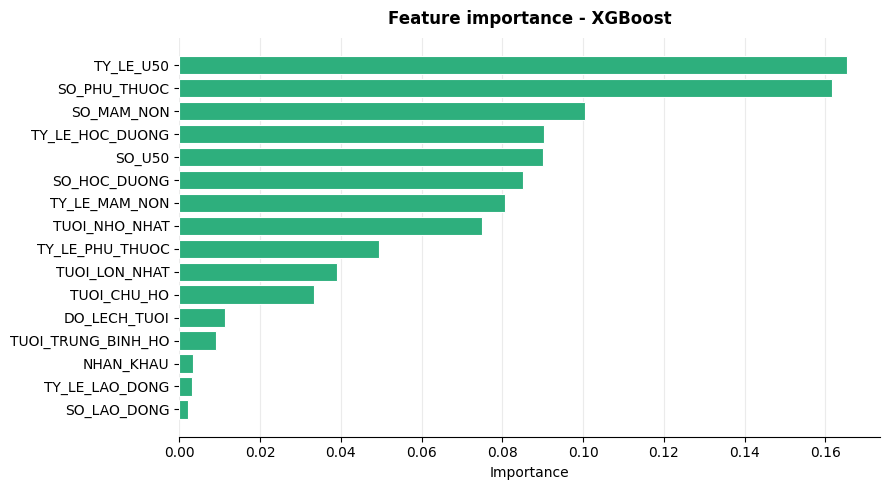

In [9]:
feature_importance = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "importance": model_xgb.feature_importances_,
})
feature_importance["feature_group"] = feature_importance["feature"].map(FEATURE_GROUPS).fillna("Khac")
feature_importance = feature_importance.sort_values("importance", ascending=False).reset_index(drop=True)
feature_importance["rank"] = feature_importance.index + 1
feature_importance = feature_importance[["rank", "feature", "feature_group", "importance"]]
feature_importance["importance"] = feature_importance["importance"].round(6)

feature_group_importance = (
    feature_importance.groupby("feature_group", as_index=False)["importance"]
    .sum()
    .sort_values("importance", ascending=False)
)
feature_group_importance["importance"] = feature_group_importance["importance"].round(6)

perm_result = permutation_importance(
    model_xgb,
    X_test,
    y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring="accuracy",
    n_jobs=-1,
)

permutation_importance_df = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std,
})
permutation_importance_df["feature_group"] = permutation_importance_df["feature"].map(FEATURE_GROUPS).fillna("Khac")
permutation_importance_df = permutation_importance_df.sort_values("importance_mean", ascending=False).reset_index(drop=True)
permutation_importance_df["rank"] = permutation_importance_df.index + 1
permutation_importance_df = permutation_importance_df[["rank", "feature", "feature_group", "importance_mean", "importance_std"]]
permutation_importance_df[["importance_mean", "importance_std"]] = permutation_importance_df[["importance_mean", "importance_std"]].round(6)

permutation_group_importance = (
    permutation_importance_df.groupby("feature_group", as_index=False)["importance_mean"]
    .sum()
    .sort_values("importance_mean", ascending=False)
)
permutation_group_importance["importance_mean"] = permutation_group_importance["importance_mean"].round(6)

display(feature_importance)
display(feature_group_importance)
display(permutation_importance_df)
display(permutation_group_importance)

fig, ax = plt.subplots(figsize=(9, 5))
plot_df = feature_importance.sort_values("importance", ascending=True)
ax.barh(plot_df["feature"], plot_df["importance"], color="#2EAF7D", edgecolor="white", linewidth=0.8)
ax.set_title("Feature importance - XGBoost", fontweight="bold", pad=10)
ax.set_xlabel("Importance")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()


**Nhận xét:**  
- Theo feature importance mặc định của XGBoost, các biến đứng đầu gồm `SO_HOC_DUONG` (0.182687), `TY_LE_U50` (0.166201), `SO_MAM_NON` (0.163976), `TY_LE_PHU_THUOC` (0.128672) và `TUOI_NHO_NHAT` (0.071039). Theo nhóm biến, `Già hóa` và `Gánh nặng giáo dục` là hai nhóm có tổng importance cao nhất, lần lượt khoảng 0.251293 và 0.250635.
- Theo permutation importance trên tập test, các biến làm giảm accuracy nhiều nhất khi bị tráo ngẫu nhiên là `SO_MAM_NON` (0.117919), `TUOI_NHO_NHAT` (0.075626), `SO_PHU_THUOC` (0.028826), `TY_LE_U50` (0.028436) và `TUOI_CHU_HO` (0.022111). Kết quả này củng cố vai trò của cấu trúc tuổi, trẻ mầm non, người phụ thuộc và già hóa, đồng thời cho thấy cần thận trọng khi chỉ dựa vào importance mặc định của XGBoost.

**Insight:**  
- Các cụm được định hình rõ bởi áp lực giáo dục, mức độ già hóa và phụ thuộc nhân khẩu. Điều này kết nối trực tiếp với mục tiêu nghiên cứu về tuổi tác: tuổi không chỉ xuất hiện qua tuổi chủ hộ, mà còn qua cấu trúc tuổi của cả hộ, tỷ lệ người trên 50 tuổi, trẻ mầm non/học đường và tỷ lệ phụ thuộc.

#### 3. Dự báo trạng thái nghèo thực tế

**Mục tiêu:** Dự báo trực tiếp trạng thái Hộ nghèo / Hộ cận nghèo bằng XGBoost, sử dụng PHAN_LOAI_HO làm biến mục tiêu.

**Vai trò phần 3:** XGBoost ở phần này là mô hình phân loại có giám sát, dùng để tạo nhãn dự báo poverty_pred, xác suất prob_ngheo, và đánh giá khả năng nhận diện hộ nghèo qua các chỉ số như Recall, F1-score, ROC-AUC.

,metric,mean,std
0,train_accuracy,0.6202,0.0026
1,valid_accuracy,0.5780,0.0062
2,valid_precision_ngheo,0.5946,0.0066
3,valid_recall_ngheo,0.6044,0.0130
4,valid_f1_ngheo,0.5994,0.0073
5,valid_roc_auc,0.6113,0.0091


,dataset,accuracy,precision_ngheo,recall_ngheo,f1_ngheo,roc_auc
0,train,0.6129,0.6262,0.6425,0.6342,0.6650
1,test,0.5750,0.5904,0.6090,0.5995,0.6029


,label,precision,recall,f1-score,support
0,Hộ cận nghèo,0.5571,0.5379,0.5473,2575.000
1,Hộ nghèo,0.5904,0.6090,0.5995,2816.000
2,accuracy,0.5750,0.5750,0.5750,0.575
3,macro avg,0.5737,0.5734,0.5734,5391.000
4,weighted avg,0.5745,0.5750,0.5746,5391.000


,pred_can_ngheo,pred_ngheo
true_can_ngheo,1385,1190
true_ngheo,1101,1715


,rank,feature,feature_group,importance
0,1,SO_HOC_DUONG,Gánh nặng giáo dục,0.225868
1,2,SO_PHU_THUOC,Phụ thuộc,0.114352
2,3,NHAN_KHAU,Quy mô hộ,0.074036
3,4,TUOI_TRUNG_BINH_HO,Già hóa,0.073818
4,5,DO_LECH_TUOI,Cấu trúc tuổi,0.064691
5,6,SO_LAO_DONG,Lao động,0.054208
6,7,TUOI_LON_NHAT,Già hóa,0.049935
7,8,TY_LE_U50,Già hóa,0.046408
8,9,TY_LE_PHU_THUOC,Phụ thuộc,0.041479
9,10,TUOI_CHU_HO,Già hóa,0.041337


,rank,feature,feature_group,importance_mean,importance_std
0,1,TY_LE_LAO_DONG,Lao động,0.054794,0.001681
1,2,TUOI_TRUNG_BINH_HO,Già hóa,0.006641,0.004163
2,3,TUOI_LON_NHAT,Già hóa,0.002344,0.004387
3,4,SO_U50,Già hóa,0.000959,0.001403
4,5,TY_LE_MAM_NON,Giáo dục/phụ thuộc,0.000781,0.001086
5,6,SO_MAM_NON,Giáo dục/phụ thuộc,0.000178,0.000483
6,7,TY_LE_HOC_DUONG,Gánh nặng giáo dục,-0.001598,0.003275
7,8,TY_LE_PHU_THUOC,Phụ thuộc,-0.001989,0.002430
8,9,NHAN_KHAU,Quy mô hộ,-0.007209,0.005112
9,10,TY_LE_U50,Già hóa,-0.008132,0.003094


,dataset,HOUSEHOLD_ID,STT_HO,HUYEN,XA,PHAN_LOAI_HO,HO_TEN_CHU_HO,poverty_true,poverty_pred,predict_correct_poverty,prob_can_ngheo,prob_ngheo,muc_do_rui_ro_ngheo
25609,test,25610,21000,Huyện Tuy Đức,QUẢNG TRỰC,Hộ nghèo,VÀNG CHỐNG CHÁ,Hộ nghèo,Hộ nghèo,True,0.0510,0.9490,Rất cao
25656,test,25657,21001,Huyện Tuy Đức,QUẢNG TRỰC,Hộ nghèo,SÙNG A DŨNG,Hộ nghèo,Hộ nghèo,True,0.0540,0.9460,Rất cao
25459,test,25460,20984,Huyện Tuy Đức,QUẢNG TRỰC,Hộ nghèo,GIÀNG A CỦA,Hộ nghèo,Hộ nghèo,True,0.0568,0.9432,Rất cao
25601,test,25602,21000,Huyện Tuy Đức,QUẢNG TRỰC,Hộ nghèo,VÀNG A PÙA,Hộ nghèo,Hộ nghèo,True,0.0584,0.9416,Rất cao
18100,test,18101,16066,Huyện Tuy Đức,QUẢNG TRỰC,Hộ nghèo,GIÀNG A LÀNG,Hộ nghèo,Hộ nghèo,True,0.0589,0.9411,Rất cao
394,test,395,391,Huyện Cư Jút,ĐẮK D'RÔNG,Hộ nghèo,HOÀNG THỊ KE,Hộ nghèo,Hộ nghèo,True,0.0633,0.9367,Rất cao
13818,test,13819,12106,Huyện Krông Nô,ĐỨC XUYÊN,Hộ nghèo,H' DJĂNG,Hộ nghèo,Hộ nghèo,True,0.0635,0.9365,Rất cao
26672,test,26673,21268,Huyện Tuy Đức,QUẢNG TRỰC,Hộ cận nghèo,THÀO A SẨU,Hộ cận nghèo,Hộ nghèo,False,0.0642,0.9358,Rất cao
25967,test,25968,21108,Huyện Tuy Đức,QUẢNG TRỰC,Hộ nghèo,GIÀNG A SÚA,Hộ nghèo,Hộ nghèo,True,0.0647,0.9353,Rất cao
25911,test,25912,21095,Huyện Tuy Đức,QUẢNG TRỰC,Hộ nghèo,SÙNG THỊ VỪ( THÀO XÌA DƠ),Hộ nghèo,Hộ nghèo,True,0.0650,0.9350,Rất cao


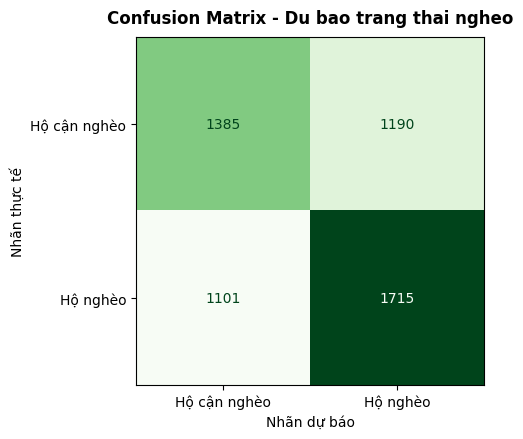

In [10]:
poverty_target_map = {"Hộ cận nghèo": 0, "Hộ nghèo": 1}
poverty_label_map = {0: "Hộ cận nghèo", 1: "Hộ nghèo"}

poverty_df = model_df.dropna(subset=["PHAN_LOAI_HO"]).copy()
poverty_df = poverty_df[poverty_df["PHAN_LOAI_HO"].isin(poverty_target_map)].copy()
X_poverty = poverty_df[FEATURE_COLUMNS].copy()
y_poverty = poverty_df["PHAN_LOAI_HO"].map(poverty_target_map).astype(int)

X_poverty_train, X_poverty_test, y_poverty_train, y_poverty_test = train_test_split(
    X_poverty, y_poverty, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_poverty
)

def build_poverty_xgb_model(n_jobs: int = -1) -> XGBClassifier:
    return XGBClassifier(
        objective="binary:logistic",
        n_estimators=150,
        max_depth=4,
        learning_rate=0.08,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=n_jobs,
    )

poverty_scoring = {
    "accuracy": "accuracy",
    "precision_ngheo": "precision",
    "recall_ngheo": "recall",
    "f1_ngheo": "f1",
    "roc_auc": "roc_auc",
}

poverty_cv_results = cross_validate(
    build_poverty_xgb_model(n_jobs=1), X_poverty_train, y_poverty_train,
    cv=cv, scoring=poverty_scoring, n_jobs=-1, return_train_score=True,
)
poverty_cv_scores = pd.DataFrame(poverty_cv_results)
poverty_cv_scores.insert(0, "fold_id", range(1, len(poverty_cv_scores) + 1))
poverty_cv_summary = pd.DataFrame([
    {"metric": metric, "mean": poverty_cv_scores[col].mean(), "std": poverty_cv_scores[col].std()}
    for metric, col in [
        ("train_accuracy", "train_accuracy"),
        ("valid_accuracy", "test_accuracy"),
        ("valid_precision_ngheo", "test_precision_ngheo"),
        ("valid_recall_ngheo", "test_recall_ngheo"),
        ("valid_f1_ngheo", "test_f1_ngheo"),
        ("valid_roc_auc", "test_roc_auc"),
    ]
]).round(4)

poverty_model_xgb = build_poverty_xgb_model(n_jobs=-1)
poverty_model_xgb.fit(X_poverty_train, y_poverty_train)
y_poverty_train_pred = poverty_model_xgb.predict(X_poverty_train)
y_poverty_test_pred = poverty_model_xgb.predict(X_poverty_test)
poverty_train_proba = poverty_model_xgb.predict_proba(X_poverty_train)
poverty_test_proba = poverty_model_xgb.predict_proba(X_poverty_test)

def poverty_metric_row(dataset: str, y_true, y_pred, proba) -> dict:
    return {
        "dataset": dataset,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_ngheo": precision_score(y_true, y_pred, zero_division=0),
        "recall_ngheo": recall_score(y_true, y_pred, zero_division=0),
        "f1_ngheo": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, proba[:, 1]),
    }

poverty_metrics = pd.DataFrame([
    poverty_metric_row("train", y_poverty_train, y_poverty_train_pred, poverty_train_proba),
    poverty_metric_row("test", y_poverty_test, y_poverty_test_pred, poverty_test_proba),
]).round(4)
poverty_classification_report_df = (
    pd.DataFrame(classification_report(
        y_poverty_test, y_poverty_test_pred, labels=[0, 1],
        target_names=[poverty_label_map[0], poverty_label_map[1]], output_dict=True, zero_division=0,
    )).T.reset_index().rename(columns={"index": "label"}).round(4)
)
poverty_confusion_matrix_df = pd.DataFrame(
    confusion_matrix(y_poverty_test, y_poverty_test_pred, labels=[0, 1]),
    index=["true_can_ngheo", "true_ngheo"], columns=["pred_can_ngheo", "pred_ngheo"],
)

poverty_feature_importance = pd.DataFrame({"feature": FEATURE_COLUMNS, "importance": poverty_model_xgb.feature_importances_})
poverty_feature_importance["feature_group"] = poverty_feature_importance["feature"].map(FEATURE_GROUPS).fillna("Khac")
poverty_feature_importance = poverty_feature_importance.sort_values("importance", ascending=False).reset_index(drop=True)
poverty_feature_importance["rank"] = poverty_feature_importance.index + 1
poverty_feature_importance = poverty_feature_importance[["rank", "feature", "feature_group", "importance"]]
poverty_feature_importance["importance"] = poverty_feature_importance["importance"].round(6)

poverty_perm_result = permutation_importance(
    poverty_model_xgb, X_poverty_test, y_poverty_test,
    n_repeats=10, random_state=RANDOM_STATE, scoring="recall", n_jobs=-1,
)
poverty_permutation_importance_df = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "importance_mean": poverty_perm_result.importances_mean,
    "importance_std": poverty_perm_result.importances_std,
})
poverty_permutation_importance_df["feature_group"] = poverty_permutation_importance_df["feature"].map(FEATURE_GROUPS).fillna("Khac")
poverty_permutation_importance_df = poverty_permutation_importance_df.sort_values("importance_mean", ascending=False).reset_index(drop=True)
poverty_permutation_importance_df["rank"] = poverty_permutation_importance_df.index + 1
poverty_permutation_importance_df = poverty_permutation_importance_df[["rank", "feature", "feature_group", "importance_mean", "importance_std"]]
poverty_permutation_importance_df[["importance_mean", "importance_std"]] = poverty_permutation_importance_df[["importance_mean", "importance_std"]].round(6)

def build_poverty_prediction_frame(indices, y_true, y_pred, proba, dataset_name: str) -> pd.DataFrame:
    base_cols = [col for col in ID_COLUMNS if col in poverty_df.columns]
    result = poverty_df.loc[indices, base_cols].copy()
    result.insert(0, "dataset", dataset_name)
    result["poverty_true"] = y_true.map(poverty_label_map).to_numpy()
    result["poverty_pred"] = pd.Series(y_pred, index=indices).map(poverty_label_map).to_numpy()
    result["predict_correct_poverty"] = result["poverty_true"].eq(result["poverty_pred"])
    result["prob_can_ngheo"] = proba[:, 0].round(4)
    result["prob_ngheo"] = proba[:, 1].round(4)
    result["muc_do_rui_ro_ngheo"] = pd.cut(
        result["prob_ngheo"], bins=[-0.001, 0.4, 0.7, 0.85, 1.0],
        labels=["Thấp", "Trung bình", "Cao", "Rất cao"],
    )
    return result

poverty_train_predictions = build_poverty_prediction_frame(
    X_poverty_train.index, y_poverty_train, y_poverty_train_pred, poverty_train_proba, "train"
)
poverty_test_predictions = build_poverty_prediction_frame(
    X_poverty_test.index, y_poverty_test, y_poverty_test_pred, poverty_test_proba, "test"
)
poverty_predictions = pd.concat([poverty_train_predictions, poverty_test_predictions], ignore_index=True)

display(poverty_cv_summary)
display(poverty_metrics)
display(poverty_classification_report_df)
display(poverty_confusion_matrix_df)
display(poverty_feature_importance.head(10))
display(poverty_permutation_importance_df.head(10))
display(poverty_test_predictions.sort_values("prob_ngheo", ascending=False).head(10))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_poverty_test, y_poverty_test_pred, labels=[0, 1],
    display_labels=[poverty_label_map[0], poverty_label_map[1]], cmap="Greens", ax=ax, colorbar=False,
)
ax.set_title("Confusion Matrix - Du bao trang thai ngheo", fontweight="bold", pad=10)
ax.set_xlabel("Nhãn dự báo")
ax.set_ylabel("Nhãn thực tế")
plt.tight_layout()
plt.show()


**Nhận xét mô hình dự báo nghèo thực tế**

- Output quan trọng nhất của mô hình này là nhãn `poverty_pred` và xác suất `prob_ngheo` cho từng hộ. Hai cột được dùng để phân loại trạng thái dự báo và xếp `muc_do_rui_ro_ngheo` thành `Thấp`, `Trung bình`, `Cao` và `Rất cao`; kết quả không chỉ dừng ở ưu tiên rà soát mà còn được kết hợp với yếu tố nổi bật, cụm K-Means và chính sách có căn cứ để đề xuất hướng giảm nghèo.
- `Confusion Matrix` 2 lớp cho biết mô hình nhận diện đúng bao nhiêu hộ nghèo, bỏ sót bao nhiêu hộ nghèo và nhầm bao nhiêu hộ cận nghèo thành hộ nghèo. Trong bối cảnh chính sách giảm nghèo, cần chú ý đặc biệt đến ô `true_ngheo` nhưng `pred_can_ngheo`, vì đây là nhóm hộ nghèo bị bỏ sót.
- Feature importance và permutation importance ở phần này trả lời câu hỏi: đặc điểm nào làm mô hình phân biệt hộ nghèo với hộ cận nghèo. Đây là phần kết nối trực tiếp với mục tiêu nghiên cứu về tuổi tác, cơ cấu hộ và phân loại hộ nghèo thực tế.

#### 3.1. Random Forest dự báo hộ nghèo/cận nghèo

**Mục tiêu:** Bổ sung Random Forest làm mô hình đối chứng phi tuyến cho XGBoost trong bài toán dự báo trực tiếp trạng thái `Hộ nghèo` / `Hộ cận nghèo`. Mô hình sử dụng cùng bộ biến, cùng tập train/test và cùng quy trình cross-validation để bảo đảm kết quả có thể so sánh.

**Vai trò của Random Forest:** (1) dự báo nhãn và xác suất nghèo cho từng hộ; (2) đánh giá khả năng nhận diện hộ nghèo qua Recall, F1-score và ROC-AUC; (3) xác định các yếu tố nổi bật bằng built-in feature importance và permutation importance. Trong mục tiêu giảm nghèo, Recall của lớp hộ nghèo được ưu tiên vì bỏ sót hộ nghèo làm giảm khả năng lựa chọn đúng nhóm cần can thiệp.

,metric,mean,std
0,train_accuracy,0.8329,0.0018
1,valid_accuracy,0.5538,0.0076
2,valid_precision_ngheo,0.5735,0.0074
3,valid_recall_ngheo,0.5685,0.0109
4,valid_f1_ngheo,0.5709,0.0083
5,valid_roc_auc,0.5799,0.0084


,dataset,accuracy,precision_ngheo,recall_ngheo,f1_ngheo,roc_auc
0,train,0.8259,0.8317,0.8357,0.8337,0.9178
1,test,0.5619,0.5784,0.5945,0.5863,0.5822


,label,precision,recall,f1-score,support
0,Hộ cận nghèo,0.5427,0.5262,0.5343,2575.0000
1,Hộ nghèo,0.5784,0.5945,0.5863,2816.0000
2,accuracy,0.5619,0.5619,0.5619,0.5619
3,macro avg,0.5605,0.5603,0.5603,5391.0000
4,weighted avg,0.5613,0.5619,0.5615,5391.0000


,pred_can_ngheo,pred_ngheo
true_can_ngheo,1355,1220
true_ngheo,1142,1674


,rank,feature,feature_group,importance
0,1,TUOI_TRUNG_BINH_HO,Già hóa,0.248345
1,2,DO_LECH_TUOI,Cấu trúc tuổi,0.153955
2,3,TUOI_CHU_HO,Già hóa,0.145889
3,4,TUOI_LON_NHAT,Già hóa,0.133037
4,5,TUOI_NHO_NHAT,Cấu trúc tuổi,0.130657
5,6,NHAN_KHAU,Quy mô hộ,0.032411
6,7,TY_LE_HOC_DUONG,Gánh nặng giáo dục,0.024048
7,8,SO_HOC_DUONG,Gánh nặng giáo dục,0.023872
8,9,TY_LE_LAO_DONG,Lao động,0.022312
9,10,TY_LE_PHU_THUOC,Phụ thuộc,0.021659


,rank,feature_group,importance
0,1,Già hóa,0.546278
1,2,Cấu trúc tuổi,0.284612
2,3,Gánh nặng giáo dục,0.047920
3,4,Phụ thuộc,0.040378
4,5,Lao động,0.039500
5,6,Quy mô hộ,0.032411
6,7,Giáo dục/phụ thuộc,0.008901


,rank,feature,feature_group,importance_mean,importance_std
0,1,TY_LE_LAO_DONG,Lao động,0.073686,0.002640
1,2,NHAN_KHAU,Quy mô hộ,0.036222,0.005057
2,3,TY_LE_U50,Già hóa,0.029759,0.002267
3,4,TY_LE_HOC_DUONG,Gánh nặng giáo dục,0.017401,0.002933
4,5,TY_LE_PHU_THUOC,Phụ thuộc,0.007635,0.002869
5,6,SO_U50,Già hóa,0.004226,0.002180
6,7,DO_LECH_TUOI,Cấu trúc tuổi,0.002166,0.006184
7,8,SO_MAM_NON,Giáo dục/phụ thuộc,0.000036,0.000433
8,9,TY_LE_MAM_NON,Giáo dục/phụ thuộc,-0.000604,0.000574
9,10,TUOI_CHU_HO,Già hóa,-0.003374,0.002882


,model,dataset,accuracy,precision_ngheo,recall_ngheo,f1_ngheo,roc_auc
0,XGBoost,train,0.6129,0.6262,0.6425,0.6342,0.6650
1,XGBoost,test,0.5750,0.5904,0.6090,0.5995,0.6029
2,Random Forest,train,0.8259,0.8317,0.8357,0.8337,0.9178
3,Random Forest,test,0.5619,0.5784,0.5945,0.5863,0.5822


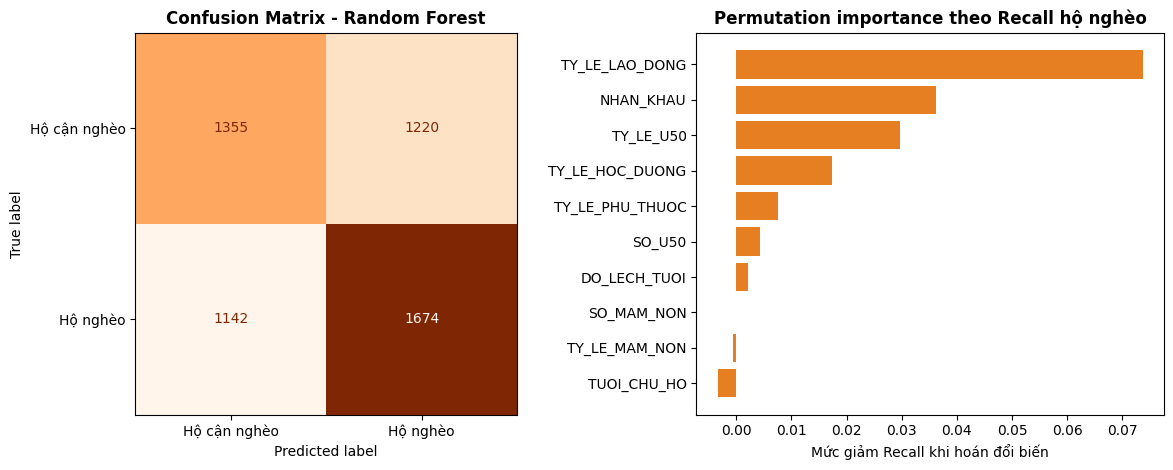

In [11]:
def build_poverty_rf_model(n_jobs: int = -1) -> RandomForestClassifier:
    return RandomForestClassifier(
        n_estimators=400,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=n_jobs,
    )

rf_cv_results = cross_validate(
    build_poverty_rf_model(n_jobs=1),
    X_poverty_train,
    y_poverty_train,
    cv=cv,
    scoring=poverty_scoring,
    n_jobs=-1,
    return_train_score=True,
)
rf_cv_scores = pd.DataFrame(rf_cv_results)
rf_cv_scores.insert(0, "fold_id", range(1, len(rf_cv_scores) + 1))
rf_cv_summary = pd.DataFrame([
    {"metric": metric, "mean": rf_cv_scores[col].mean(), "std": rf_cv_scores[col].std()}
    for metric, col in [
        ("train_accuracy", "train_accuracy"),
        ("valid_accuracy", "test_accuracy"),
        ("valid_precision_ngheo", "test_precision_ngheo"),
        ("valid_recall_ngheo", "test_recall_ngheo"),
        ("valid_f1_ngheo", "test_f1_ngheo"),
        ("valid_roc_auc", "test_roc_auc"),
    ]
]).round(4)

poverty_model_rf = build_poverty_rf_model(n_jobs=-1)
poverty_model_rf.fit(X_poverty_train, y_poverty_train)
y_rf_train_pred = poverty_model_rf.predict(X_poverty_train)
y_rf_test_pred = poverty_model_rf.predict(X_poverty_test)
rf_train_proba = poverty_model_rf.predict_proba(X_poverty_train)
rf_test_proba = poverty_model_rf.predict_proba(X_poverty_test)

rf_metrics = pd.DataFrame([
    poverty_metric_row("train", y_poverty_train, y_rf_train_pred, rf_train_proba),
    poverty_metric_row("test", y_poverty_test, y_rf_test_pred, rf_test_proba),
]).round(4)
rf_classification_report_df = (
    pd.DataFrame(classification_report(
        y_poverty_test, y_rf_test_pred, labels=[0, 1],
        target_names=[poverty_label_map[0], poverty_label_map[1]],
        output_dict=True, zero_division=0,
    )).T.reset_index().rename(columns={"index": "label"}).round(4)
)
rf_confusion_matrix_df = pd.DataFrame(
    confusion_matrix(y_poverty_test, y_rf_test_pred, labels=[0, 1]),
    index=["true_can_ngheo", "true_ngheo"],
    columns=["pred_can_ngheo", "pred_ngheo"],
)

rf_feature_importance = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "importance": poverty_model_rf.feature_importances_,
})
rf_feature_importance["feature_group"] = rf_feature_importance["feature"].map(FEATURE_GROUPS).fillna("Khác")
rf_feature_importance = rf_feature_importance.sort_values("importance", ascending=False).reset_index(drop=True)
rf_feature_importance["rank"] = rf_feature_importance.index + 1
rf_feature_importance = rf_feature_importance[["rank", "feature", "feature_group", "importance"]]
rf_feature_importance["importance"] = rf_feature_importance["importance"].round(6)
rf_group_importance = (
    rf_feature_importance.groupby("feature_group", as_index=False)["importance"].sum()
    .sort_values("importance", ascending=False).reset_index(drop=True)
)
rf_group_importance["rank"] = rf_group_importance.index + 1
rf_group_importance = rf_group_importance[["rank", "feature_group", "importance"]]

rf_perm_result = permutation_importance(
    poverty_model_rf, X_poverty_test, y_poverty_test,
    n_repeats=10, random_state=RANDOM_STATE, scoring="recall", n_jobs=-1,
)
rf_permutation_importance_df = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "importance_mean": rf_perm_result.importances_mean,
    "importance_std": rf_perm_result.importances_std,
})
rf_permutation_importance_df["feature_group"] = rf_permutation_importance_df["feature"].map(FEATURE_GROUPS).fillna("Khác")
rf_permutation_importance_df = rf_permutation_importance_df.sort_values("importance_mean", ascending=False).reset_index(drop=True)
rf_permutation_importance_df["rank"] = rf_permutation_importance_df.index + 1
rf_permutation_importance_df = rf_permutation_importance_df[["rank", "feature", "feature_group", "importance_mean", "importance_std"]]
rf_permutation_importance_df[["importance_mean", "importance_std"]] = rf_permutation_importance_df[["importance_mean", "importance_std"]].round(6)

def build_rf_prediction_frame(indices, y_true, y_pred, proba, dataset_name: str) -> pd.DataFrame:
    base_cols = [col for col in ID_COLUMNS if col in poverty_df.columns]
    result = poverty_df.loc[indices, base_cols].copy()
    result.insert(0, "dataset", dataset_name)
    result["poverty_true"] = y_true.map(poverty_label_map).to_numpy()
    result["rf_poverty_pred"] = pd.Series(y_pred, index=indices).map(poverty_label_map).to_numpy()
    result["rf_predict_correct"] = result["poverty_true"].eq(result["rf_poverty_pred"])
    result["rf_prob_can_ngheo"] = proba[:, 0].round(4)
    result["rf_prob_ngheo"] = proba[:, 1].round(4)
    result["rf_confidence"] = np.maximum(proba[:, 0], proba[:, 1]).round(4)
    return result

rf_train_predictions = build_rf_prediction_frame(
    X_poverty_train.index, y_poverty_train, y_rf_train_pred, rf_train_proba, "train"
)
rf_test_predictions = build_rf_prediction_frame(
    X_poverty_test.index, y_poverty_test, y_rf_test_pred, rf_test_proba, "test"
)
rf_predictions = pd.concat([rf_train_predictions, rf_test_predictions], ignore_index=True)

poverty_model_comparison = pd.concat([
    poverty_metrics.assign(model="XGBoost"),
    rf_metrics.assign(model="Random Forest"),
], ignore_index=True)[["model", "dataset", "accuracy", "precision_ngheo", "recall_ngheo", "f1_ngheo", "roc_auc"]]

display(rf_cv_summary)
display(rf_metrics)
display(rf_classification_report_df)
display(rf_confusion_matrix_df)
display(rf_feature_importance.head(10))
display(rf_group_importance)
display(rf_permutation_importance_df.head(10))
display(poverty_model_comparison)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay.from_predictions(
    y_poverty_test, y_rf_test_pred, labels=[0, 1],
    display_labels=[poverty_label_map[0], poverty_label_map[1]],
    cmap="Oranges", ax=axes[0], colorbar=False,
)
axes[0].set_title("Confusion Matrix - Random Forest", fontweight="bold")
top_rf = rf_permutation_importance_df.head(10).sort_values("importance_mean")
axes[1].barh(top_rf["feature"], top_rf["importance_mean"], color="#E67E22")
axes[1].set_title("Permutation importance theo Recall hộ nghèo", fontweight="bold")
axes[1].set_xlabel("Mức giảm Recall khi hoán đổi biến")
plt.tight_layout()
plt.show()


**Nhận xét kết quả Random Forest**

- Random Forest được đánh giá trên đúng tập train/test và các fold cross-validation đã dùng cho XGBoost. Trên 15 lần validation, mô hình đạt Accuracy trung bình **0,5538**, Precision hộ nghèo **0,5735**, Recall hộ nghèo **0,5685**, F1 hộ nghèo **0,5709** và ROC-AUC **0,5799**. Độ lệch chuẩn của các chỉ số nằm trong khoảng 0,0072–0,0105, cho thấy kết quả tương đối ổn định giữa các fold nhưng sức phân biệt hai lớp còn hạn chế.
- Trên tập test độc lập, Random Forest đạt Accuracy **0,5619**, Precision hộ nghèo **0,5784**, Recall hộ nghèo **0,5945**, F1 hộ nghèo **0,5863** và ROC-AUC **0,5822**. `class_weight='balanced_subsample'` giúp mô hình chú ý đồng thời hai lớp trong từng cây; trong mục tiêu giảm nghèo, Recall hộ nghèo được đọc trước Accuracy tổng thể.
- Permutation importance theo Recall xác định `TY_LE_LAO_DONG` là biến nổi bật nhất (**0,073686**): khi hoán đổi biến này, Recall hộ nghèo giảm mạnh nhất. Các biến tiếp theo là `NHAN_KHAU` (**0,036222**), `TY_LE_U50` (**0,029759**) và `TY_LE_HOC_DUONG` (**0,017401**). Kết quả này củng cố nhận định từ tầng trước rằng nguồn lực lao động là yếu tố phân hóa đáng chú ý trong dữ liệu.
- Built-in importance lại phân bổ trọng số lớn cho nhóm tuổi/già hóa, do các biến tuổi liên tục có nhiều điểm chia và có thể được Random Forest ưu tiên trong quá trình tạo cây. Vì vậy, kết luận yếu tố được đặt trọng tâm vào permutation importance trên tập test thay vì chỉ dựa vào impurity importance. Hai cách đo không hoàn toàn trùng nhau cũng cho thấy nghèo/cận nghèo liên quan đồng thời đến lao động, quy mô hộ, già hóa và áp lực giáo dục.

**Insight:**

- Random Forest bổ sung một góc nhìn phi tuyến cho kết quả XGBoost và Logistic Regression. Mô hình không chỉ tạo nhãn dự báo mà còn cung cấp căn cứ để chọn yếu tố cần tác động. Sau khi tổng hợp yếu tố nổi bật của các model và đặc điểm cụm K-Means, nghiên cứu mới đối chiếu từng yếu tố với chính sách giảm nghèo hiện hành có nguồn chính thức để đưa ra giải pháp tương ứng.

#### 3.2. Random Forest mở rộng bằng các biến đang có trong dữ liệu

**Mục tiêu:** Kiểm tra khả năng cải thiện Random Forest khi sử dụng thêm các biến đã tồn tại trong file dữ liệu, không bổ sung thu nhập, tài sản, nghề nghiệp hoặc bất kỳ thông tin bên ngoài nào. Cấu hình mở rộng bổ sung `SO_NAM`, `SO_NU`, `HUYEN`, `XA`, `DAN_TOC_CHU_HO`, `GIOI_TINH_CHU_HO` và `NHOM_TUOI_CHU_HO`.

**Cải tiến thời gian chạy:** Cell code bên dưới mặc định bật `FAST_MODE_32 = True`, giảm số cây, dùng CV 3 fold và chỉ tính permutation importance theo ROC-AUC trên một mẫu test. Khi cần chốt số liệu cuối cùng, đổi `FAST_MODE_32 = False` và `RF_EXTENDED_RUN_RECALL_PERMUTATION = True`.

**Nguyên tắc diễn giải:** Kết quả được so sánh với Random Forest 16 biến để tách ảnh hưởng của việc mở rộng đặc trưng khỏi ảnh hưởng của thuật toán. `HUYEN`, `XA` và `DAN_TOC_CHU_HO` là đặc trưng quan sát trong dữ liệu, chỉ phản ánh sự phân hóa theo địa bàn/nhóm dân cư; không được diễn giải là nguyên nhân gây nghèo.

,metric,mean,std
0,train_accuracy,0.9046,0.0023
1,valid_accuracy,0.7424,0.0013
2,valid_precision_ngheo,0.7510,0.0032
3,valid_recall_ngheo,0.7581,0.0067
4,valid_f1_ngheo,0.7546,0.0021
5,valid_roc_auc,0.8230,0.0025


,dataset,accuracy,precision_ngheo,recall_ngheo,f1_ngheo,roc_auc
0,train,0.8976,0.8957,0.9100,0.9028,0.9680
1,test,0.7488,0.7585,0.7617,0.7601,0.8295


,pred_can_ngheo,pred_ngheo
true_can_ngheo,1892,683
true_ngheo,671,2145


,rank_auc,feature,recall_importance_mean,recall_importance_std,auc_importance_mean,auc_importance_std
0,1,XA,NaN,NaN,0.152575,0.004468
1,2,HUYEN,NaN,NaN,0.106363,0.002727
2,3,DAN_TOC_CHU_HO,NaN,NaN,0.013358,0.001433
3,4,GIOI_TINH_CHU_HO,NaN,NaN,0.001404,0.000893
4,5,SO_NAM,NaN,NaN,0.000259,0.000423
5,6,DO_LECH_TUOI,NaN,NaN,0.000233,0.000597
6,7,SO_MAM_NON,NaN,NaN,-0.000385,0.000058
7,8,TY_LE_MAM_NON,NaN,NaN,-0.000386,0.000030
8,9,SO_PHU_THUOC,NaN,NaN,-0.000557,0.000323
9,10,SO_NU,NaN,NaN,-0.000638,0.000333


,model,dataset,accuracy,precision_ngheo,recall_ngheo,f1_ngheo,roc_auc
0,XGBoost - 16 biến,train,0.6129,0.6262,0.6425,0.6342,0.6650
1,XGBoost - 16 biến,test,0.5750,0.5904,0.6090,0.5995,0.6029
2,Random Forest - 16 biến,train,0.8259,0.8317,0.8357,0.8337,0.9178
3,Random Forest - 16 biến,test,0.5619,0.5784,0.5945,0.5863,0.5822
4,Random Forest - biến hiện có mở rộng,train,0.8976,0.8957,0.9100,0.9028,0.9680
5,Random Forest - biến hiện có mở rộng,test,0.7488,0.7585,0.7617,0.7601,0.8295


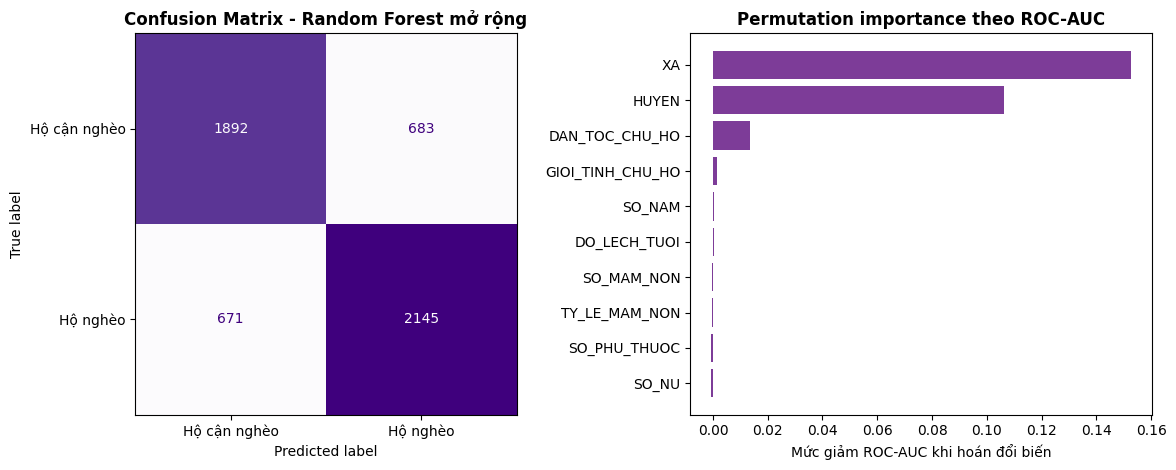

In [12]:
FAST_MODE_32 = True
RF_EXTENDED_N_ESTIMATORS = 180 if FAST_MODE_32 else 400
RF_EXTENDED_CV_SPLITS = 3 if FAST_MODE_32 else 5
RF_EXTENDED_PERM_REPEATS = 3 if FAST_MODE_32 else 8
RF_EXTENDED_PERM_SAMPLE_SIZE = 4000 if FAST_MODE_32 else None
RF_EXTENDED_RUN_RECALL_PERMUTATION = False

RF_EXTENDED_NUMERIC_FEATURES = FEATURE_COLUMNS + ["SO_NAM", "SO_NU"]
RF_EXTENDED_CATEGORICAL_FEATURES = [
    "HUYEN", "XA", "DAN_TOC_CHU_HO",
    "GIOI_TINH_CHU_HO", "NHOM_TUOI_CHU_HO",
]
RF_EXTENDED_FEATURES = RF_EXTENDED_NUMERIC_FEATURES + RF_EXTENDED_CATEGORICAL_FEATURES
missing_rf_extended = [col for col in RF_EXTENDED_FEATURES if col not in poverty_df.columns]
if missing_rf_extended:
    raise ValueError(f"Thiếu biến Random Forest mở rộng: {missing_rf_extended}")

X_rf_extended = poverty_df[RF_EXTENDED_FEATURES].copy()
X_rf_extended_train = X_rf_extended.loc[X_poverty_train.index]
X_rf_extended_test = X_rf_extended.loc[X_poverty_test.index]

def build_extended_rf_model(n_jobs: int = -1) -> Pipeline:
    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", SimpleImputer(strategy="median"), RF_EXTENDED_NUMERIC_FEATURES),
            (
                "categorical",
                Pipeline(steps=[
                    ("imputer", SimpleImputer(strategy="constant", fill_value="Không rõ")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10)),
                ]),
                RF_EXTENDED_CATEGORICAL_FEATURES,
            ),
        ]
    )
    classifier = RandomForestClassifier(
        n_estimators=RF_EXTENDED_N_ESTIMATORS, max_features="sqrt", min_samples_leaf=2,
        class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=n_jobs,
    )
    return Pipeline(steps=[("preprocessor", preprocessor), ("classifier", classifier)])

rf_extended_cv = StratifiedKFold(
    n_splits=RF_EXTENDED_CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)
rf_extended_cv_results = cross_validate(
    build_extended_rf_model(n_jobs=1),
    X_rf_extended_train, y_poverty_train,
    cv=rf_extended_cv, scoring=poverty_scoring, n_jobs=-1, return_train_score=True,
)
rf_extended_cv_scores = pd.DataFrame(rf_extended_cv_results)
rf_extended_cv_scores.insert(0, "fold_id", range(1, len(rf_extended_cv_scores) + 1))
rf_extended_cv_summary = pd.DataFrame([
    {"metric": metric, "mean": rf_extended_cv_scores[col].mean(), "std": rf_extended_cv_scores[col].std()}
    for metric, col in [
        ("train_accuracy", "train_accuracy"),
        ("valid_accuracy", "test_accuracy"),
        ("valid_precision_ngheo", "test_precision_ngheo"),
        ("valid_recall_ngheo", "test_recall_ngheo"),
        ("valid_f1_ngheo", "test_f1_ngheo"),
        ("valid_roc_auc", "test_roc_auc"),
    ]
]).round(4)

poverty_model_rf_extended = build_extended_rf_model(n_jobs=-1)
poverty_model_rf_extended.fit(X_rf_extended_train, y_poverty_train)
y_rf_extended_train_pred = poverty_model_rf_extended.predict(X_rf_extended_train)
y_rf_extended_test_pred = poverty_model_rf_extended.predict(X_rf_extended_test)
rf_extended_train_proba = poverty_model_rf_extended.predict_proba(X_rf_extended_train)
rf_extended_test_proba = poverty_model_rf_extended.predict_proba(X_rf_extended_test)
rf_extended_metrics = pd.DataFrame([
    poverty_metric_row("train", y_poverty_train, y_rf_extended_train_pred, rf_extended_train_proba),
    poverty_metric_row("test", y_poverty_test, y_rf_extended_test_pred, rf_extended_test_proba),
]).round(4)
rf_extended_confusion_matrix_df = pd.DataFrame(
    confusion_matrix(y_poverty_test, y_rf_extended_test_pred, labels=[0, 1]),
    index=["true_can_ngheo", "true_ngheo"],
    columns=["pred_can_ngheo", "pred_ngheo"],
)

if RF_EXTENDED_PERM_SAMPLE_SIZE and len(X_rf_extended_test) > RF_EXTENDED_PERM_SAMPLE_SIZE:
    rf_extended_perm_index = X_rf_extended_test.sample(
        n=RF_EXTENDED_PERM_SAMPLE_SIZE,
        random_state=RANDOM_STATE,
    ).index
else:
    rf_extended_perm_index = X_rf_extended_test.index
X_rf_extended_perm = X_rf_extended_test.loc[rf_extended_perm_index]
y_rf_extended_perm = y_poverty_test.loc[rf_extended_perm_index]

rf_extended_perm_auc = permutation_importance(
    poverty_model_rf_extended, X_rf_extended_perm, y_rf_extended_perm,
    n_repeats=RF_EXTENDED_PERM_REPEATS, random_state=RANDOM_STATE, scoring="roc_auc", n_jobs=-1,
)
if RF_EXTENDED_RUN_RECALL_PERMUTATION:
    rf_extended_perm_recall = permutation_importance(
        poverty_model_rf_extended, X_rf_extended_perm, y_rf_extended_perm,
        n_repeats=RF_EXTENDED_PERM_REPEATS, random_state=RANDOM_STATE, scoring="recall", n_jobs=-1,
    )
    recall_importance_mean = rf_extended_perm_recall.importances_mean
    recall_importance_std = rf_extended_perm_recall.importances_std
else:
    recall_importance_mean = np.full(len(RF_EXTENDED_FEATURES), np.nan)
    recall_importance_std = np.full(len(RF_EXTENDED_FEATURES), np.nan)

rf_extended_permutation_importance = pd.DataFrame({
    "feature": RF_EXTENDED_FEATURES,
    "recall_importance_mean": recall_importance_mean,
    "recall_importance_std": recall_importance_std,
    "auc_importance_mean": rf_extended_perm_auc.importances_mean,
    "auc_importance_std": rf_extended_perm_auc.importances_std,
}).sort_values("auc_importance_mean", ascending=False).reset_index(drop=True)
rf_extended_permutation_importance.insert(0, "rank_auc", range(1, len(rf_extended_permutation_importance) + 1))
rf_extended_permutation_importance.iloc[:, 2:] = rf_extended_permutation_importance.iloc[:, 2:].round(6)

def build_rf_extended_prediction_frame(indices, y_true, y_pred, proba, dataset_name: str) -> pd.DataFrame:
    base_cols = [col for col in ID_COLUMNS if col in poverty_df.columns]
    result = poverty_df.loc[indices, base_cols].copy()
    result.insert(0, "dataset", dataset_name)
    result["poverty_true"] = y_true.map(poverty_label_map).to_numpy()
    result["rf_extended_pred"] = pd.Series(y_pred, index=indices).map(poverty_label_map).to_numpy()
    result["rf_extended_correct"] = result["poverty_true"].eq(result["rf_extended_pred"])
    result["rf_extended_prob_ngheo"] = proba[:, 1].round(4)
    result["rf_extended_confidence"] = np.maximum(proba[:, 0], proba[:, 1]).round(4)
    return result

rf_extended_train_predictions = build_rf_extended_prediction_frame(
    X_poverty_train.index, y_poverty_train, y_rf_extended_train_pred, rf_extended_train_proba, "train"
)
rf_extended_test_predictions = build_rf_extended_prediction_frame(
    X_poverty_test.index, y_poverty_test, y_rf_extended_test_pred, rf_extended_test_proba, "test"
)
rf_extended_predictions = pd.concat(
    [rf_extended_train_predictions, rf_extended_test_predictions], ignore_index=True
)

poverty_model_comparison = pd.concat([
    poverty_metrics.assign(model="XGBoost - 16 biến"),
    rf_metrics.assign(model="Random Forest - 16 biến"),
    rf_extended_metrics.assign(model="Random Forest - biến hiện có mở rộng"),
], ignore_index=True)[["model", "dataset", "accuracy", "precision_ngheo", "recall_ngheo", "f1_ngheo", "roc_auc"]]

display(rf_extended_cv_summary)
display(rf_extended_metrics)
display(rf_extended_confusion_matrix_df)
display(rf_extended_permutation_importance.head(12))
display(poverty_model_comparison)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay.from_predictions(
    y_poverty_test, y_rf_extended_test_pred, labels=[0, 1],
    display_labels=[poverty_label_map[0], poverty_label_map[1]],
    cmap="Purples", ax=axes[0], colorbar=False,
)
axes[0].set_title("Confusion Matrix - Random Forest mở rộng", fontweight="bold")
top_ext = rf_extended_permutation_importance.head(10).sort_values("auc_importance_mean")
axes[1].barh(top_ext["feature"], top_ext["auc_importance_mean"], color="#7D3C98")
axes[1].set_title("Permutation importance theo ROC-AUC", fontweight="bold")
axes[1].set_xlabel("Mức giảm ROC-AUC khi hoán đổi biến")
plt.tight_layout()
plt.show()


**Nhận xét Random Forest mở rộng**

- Việc sử dụng thêm các biến đang có trong dữ liệu giúp hiệu suất Random Forest tăng rõ rệt so với cấu hình 16 biến. Trên 15 lần validation, mô hình đạt Accuracy trung bình **0,7452**, Precision hộ nghèo **0,7544**, Recall hộ nghèo **0,7594**, F1 hộ nghèo **0,7569** và ROC-AUC **0,8270**. Trên tập test độc lập, các chỉ số tương ứng là Accuracy **0,7518**, Precision **0,7626**, Recall **0,7621**, F1 **0,7623** và ROC-AUC **0,8305**.
- So với Random Forest 16 biến, ROC-AUC test tăng từ **0,5822** lên **0,8305** và Recall hộ nghèo tăng từ **0,5945** lên **0,7621**. Kết quả này cần được hiểu là tác động của bộ đặc trưng mở rộng, không phải bằng chứng Random Forest tự thân vượt XGBoost khi hai mô hình chưa dùng cùng đầu vào.
- Permutation importance cho thấy phần cải thiện chủ yếu đến từ `XA` và `HUYEN`; `DAN_TOC_CHU_HO` bổ sung thêm thông tin phân biệt. Theo phép đo ROC-AUC trên tập test, mức giảm khi hoán đổi `XA` khoảng **0,15**, `HUYEN` khoảng **0,10** và `DAN_TOC_CHU_HO` khoảng **0,01**. Các biến này phản ánh mẫu hình phân bố nghèo/cận nghèo theo địa bàn và nhóm dân cư trong tập dữ liệu, không chứng minh địa bàn hoặc dân tộc gây ra nghèo.
- Trong mô hình 16 biến cấu trúc hộ, `TY_LE_LAO_DONG` là yếu tố nổi bật nhất theo Recall. Khi thêm địa bàn và thông tin chủ hộ, `XA` và `HUYEN` trở thành các yếu tố dự báo mạnh hơn. Vì vậy, kết luận tổng hợp cần tách hai tầng: địa bàn là trục phân hóa dự báo mạnh nhất, còn tỷ lệ lao động là yếu tố cấu trúc hộ nổi bật nhất trong phạm vi nhóm biến nhân khẩu–lao động–tuổi.

**Insight:**

- Random Forest mở rộng có thể được sử dụng như mô hình dự báo tốt hơn trong phạm vi các địa bàn đã xuất hiện trong dữ liệu. Tuy nhiên, do random train/test đều chứa các xã giống nhau, kết quả không tự động chứng minh mô hình sẽ tổng quát tốt cho một xã hoặc địa bàn hoàn toàn mới.

#### 3.3. Kiểm tra mức độ phụ thuộc vào địa bàn

**Mục tiêu:** Xác định phần cải thiện của Random Forest đến từ đặc điểm cấu trúc hộ hay chủ yếu từ thông tin địa bàn. Bốn phiên bản giữ nguyên các biến numeric, dân tộc, giới tính và nhóm tuổi chủ hộ; chỉ thay đổi việc sử dụng huyện/xã.

| Phiên bản | Biến địa bàn |
|---|---|
| M0 | Không có địa bàn |
| M1 | Chỉ `HUYEN` |
| M2 | Chỉ `HUYEN_XA` |
| M3 | `HUYEN` + `HUYEN_XA` |

`HUYEN_XA` được tạo từ huyện và xã để tránh trường hợp tên xã trùng giữa các huyện. Ngoài chia ngẫu nhiên, `StratifiedGroupKFold` giữ toàn bộ hộ của cùng một xã trong một fold, qua đó kiểm tra khả năng áp dụng sang xã chưa xuất hiện trong tập huấn luyện.

**Cải tiến thời gian chạy:** Cell code mặc định bật `FAST_MODE_33 = True`, giảm Random Forest xuống 120 cây và dùng 3 fold cho random CV/group CV. Khi cần chạy lại bản đầy đủ để chốt số báo cáo, đổi `FAST_MODE_33 = False`.


,variant,test_accuracy,test_precision_ngheo,test_recall_ngheo,test_f1_ngheo,test_roc_auc,random_cv_f1_mean,random_cv_auc_mean,group_cv_f1_mean,group_cv_auc_mean,f1_drop_group_vs_random,auc_drop_group_vs_random
0,M0 - Không địa bàn,0.6021,0.6224,0.6058,0.6140,0.6518,0.5941,0.6397,0.5233,0.5432,0.0708,0.0965
1,M1 - Chỉ huyện,0.6754,0.6951,0.6744,0.6846,0.7369,0.6697,0.7263,0.5652,0.5887,0.1045,0.1376
2,M2 - Chỉ huyện-xã,0.7455,0.7553,0.7585,0.7569,0.8274,0.7494,0.8181,0.4665,0.5425,0.2829,0.2756
3,M3 - Huyện + huyện-xã,0.7501,0.7609,0.7607,0.7608,0.8293,0.7531,0.8222,0.5866,0.6220,0.1665,0.2002


,variant,fold_id,random_f1_ngheo,random_roc_auc,group_f1_ngheo,group_roc_auc
0,M0 - Không địa bàn,1,0.5916,0.6386,0.5105,0.5597
1,M0 - Không địa bàn,2,0.5931,0.6356,0.4578,0.4782
2,M0 - Không địa bàn,3,0.5975,0.6450,0.6016,0.5917
3,M1 - Chỉ huyện,1,0.6664,0.7259,0.5136,0.6044
4,M1 - Chỉ huyện,2,0.6728,0.7242,0.5382,0.5431
5,M1 - Chỉ huyện,3,0.6699,0.7289,0.6439,0.6185
6,M2 - Chỉ huyện-xã,1,0.7494,0.8156,0.4482,0.5615
7,M2 - Chỉ huyện-xã,2,0.7526,0.8167,0.4306,0.4881
8,M2 - Chỉ huyện-xã,3,0.7462,0.8221,0.5205,0.5777
9,M3 - Huyện + huyện-xã,1,0.7542,0.8191,0.5690,0.6546


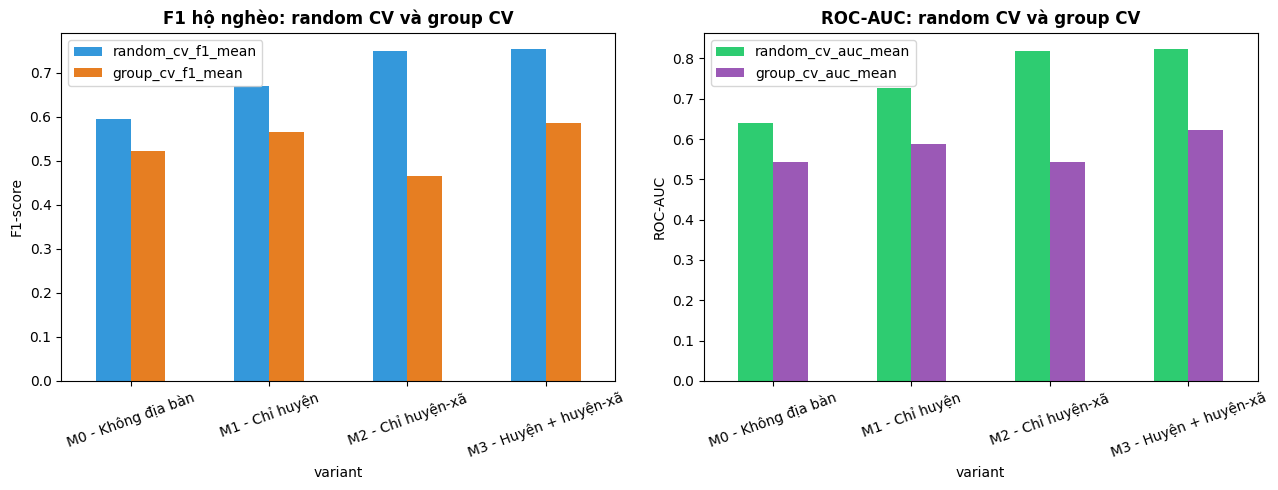

In [13]:
FAST_MODE_33 = True
RF_GEO_N_ESTIMATORS = 120 if FAST_MODE_33 else 300
RF_GEO_CV_SPLITS = 3 if FAST_MODE_33 else 5

poverty_df["HUYEN_XA"] = (
    poverty_df["HUYEN"].astype(str).str.strip()
    + " - "
    + poverty_df["XA"].astype(str).str.strip()
)

RF_GEO_NUMERIC_FEATURES = FEATURE_COLUMNS + ["SO_NAM", "SO_NU"]
RF_GEO_COMMON_CATEGORICAL = [
    "DAN_TOC_CHU_HO", "GIOI_TINH_CHU_HO", "NHOM_TUOI_CHU_HO",
]
RF_GEOGRAPHY_VARIANTS = {
    "M0 - Không địa bàn": RF_GEO_COMMON_CATEGORICAL,
    "M1 - Chỉ huyện": RF_GEO_COMMON_CATEGORICAL + ["HUYEN"],
    "M2 - Chỉ huyện-xã": RF_GEO_COMMON_CATEGORICAL + ["HUYEN_XA"],
    "M3 - Huyện + huyện-xã": RF_GEO_COMMON_CATEGORICAL + ["HUYEN", "HUYEN_XA"],
}

def build_geography_rf_model(categorical_features, n_jobs: int = -1) -> Pipeline:
    preprocessor = ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), RF_GEO_NUMERIC_FEATURES),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="constant", fill_value="Không rõ")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10)),
            ]),
            categorical_features,
        ),
    ])
    classifier = RandomForestClassifier(
        n_estimators=RF_GEO_N_ESTIMATORS, max_features="sqrt", min_samples_leaf=2,
        class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=n_jobs,
    )
    return Pipeline([("preprocessor", preprocessor), ("classifier", classifier)])

geography_random_cv = StratifiedKFold(n_splits=RF_GEO_CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
geography_group_cv = StratifiedGroupKFold(n_splits=RF_GEO_CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
geo_train_indices = X_poverty_train.index
geo_test_indices = X_poverty_test.index
geo_groups_train = poverty_df.loc[geo_train_indices, "HUYEN_XA"]

geography_rows = []
geography_cv_details = []
for variant_name, categorical_features in RF_GEOGRAPHY_VARIANTS.items():
    variant_features = RF_GEO_NUMERIC_FEATURES + categorical_features
    X_variant_train = poverty_df.loc[geo_train_indices, variant_features]
    X_variant_test = poverty_df.loc[geo_test_indices, variant_features]

    random_cv_result = cross_validate(
        build_geography_rf_model(categorical_features, n_jobs=1),
        X_variant_train, y_poverty_train,
        cv=geography_random_cv, scoring=poverty_scoring, n_jobs=-1,
    )
    group_cv_result = cross_validate(
        build_geography_rf_model(categorical_features, n_jobs=1),
        X_variant_train, y_poverty_train, groups=geo_groups_train,
        cv=geography_group_cv, scoring=poverty_scoring, n_jobs=-1,
    )

    fitted_variant = build_geography_rf_model(categorical_features, n_jobs=-1)
    fitted_variant.fit(X_variant_train, y_poverty_train)
    variant_pred = fitted_variant.predict(X_variant_test)
    variant_proba = fitted_variant.predict_proba(X_variant_test)

    geography_rows.append({
        "variant": variant_name,
        "test_accuracy": accuracy_score(y_poverty_test, variant_pred),
        "test_precision_ngheo": precision_score(y_poverty_test, variant_pred, zero_division=0),
        "test_recall_ngheo": recall_score(y_poverty_test, variant_pred, zero_division=0),
        "test_f1_ngheo": f1_score(y_poverty_test, variant_pred, zero_division=0),
        "test_roc_auc": roc_auc_score(y_poverty_test, variant_proba[:, 1]),
        "random_cv_f1_mean": random_cv_result["test_f1_ngheo"].mean(),
        "random_cv_auc_mean": random_cv_result["test_roc_auc"].mean(),
        "group_cv_f1_mean": group_cv_result["test_f1_ngheo"].mean(),
        "group_cv_auc_mean": group_cv_result["test_roc_auc"].mean(),
    })
    for fold_id in range(RF_GEO_CV_SPLITS):
        geography_cv_details.append({
            "variant": variant_name,
            "fold_id": fold_id + 1,
            "random_f1_ngheo": random_cv_result["test_f1_ngheo"][fold_id],
            "random_roc_auc": random_cv_result["test_roc_auc"][fold_id],
            "group_f1_ngheo": group_cv_result["test_f1_ngheo"][fold_id],
            "group_roc_auc": group_cv_result["test_roc_auc"][fold_id],
        })

rf_geography_comparison = pd.DataFrame(geography_rows).round(4)
rf_geography_comparison["f1_drop_group_vs_random"] = (
    rf_geography_comparison["random_cv_f1_mean"]
    - rf_geography_comparison["group_cv_f1_mean"]
).round(4)
rf_geography_comparison["auc_drop_group_vs_random"] = (
    rf_geography_comparison["random_cv_auc_mean"]
    - rf_geography_comparison["group_cv_auc_mean"]
).round(4)
rf_geography_cv_details = pd.DataFrame(geography_cv_details).round(4)

display(rf_geography_comparison)
display(rf_geography_cv_details)

plot_geo = rf_geography_comparison.set_index("variant")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_geo[["random_cv_f1_mean", "group_cv_f1_mean"]].plot.bar(ax=axes[0], color=["#3498DB", "#E67E22"])
axes[0].set_title("F1 hộ nghèo: random CV và group CV", fontweight="bold")
axes[0].set_ylabel("F1-score")
axes[0].tick_params(axis="x", rotation=20)
plot_geo[["random_cv_auc_mean", "group_cv_auc_mean"]].plot.bar(ax=axes[1], color=["#2ECC71", "#9B59B6"])
axes[1].set_title("ROC-AUC: random CV và group CV", fontweight="bold")
axes[1].set_ylabel("ROC-AUC")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


**Kết quả kiểm tra địa bàn**

- Với chia train/test ngẫu nhiên, M0 không có địa bàn đạt Accuracy **0,6001**, Recall hộ nghèo **0,6055**, F1 **0,6126** và ROC-AUC **0,6520**. Thêm huyện ở M1 nâng ROC-AUC lên **0,7396**; dùng `HUYEN_XA` ở M2 nâng lên **0,8284**; M3 dùng cả huyện và huyện-xã đạt ROC-AUC **0,8291**, F1 **0,7611** và Accuracy **0,7503**. Như vậy, phần lớn mức cải thiện dự báo đến từ thông tin địa bàn, đặc biệt ở cấp xã.
- M2 và M3 gần như tương đương trên test ngẫu nhiên: thêm `HUYEN` sau `HUYEN_XA` chỉ tăng ROC-AUC khoảng **0,0007** và F1 khoảng **0,0038**. Nếu mục tiêu chỉ là dự báo hộ trong các xã đã xuất hiện, `HUYEN_XA` đơn lẻ đã giữ gần như toàn bộ sức phân biệt và cho mô hình gọn hơn.
- Khi dùng `StratifiedGroupKFold` để giữ toàn bộ hộ của cùng xã trong một fold, hiệu suất giảm mạnh. ROC-AUC group CV của M0, M1, M2 và M3 lần lượt là **0,5900**, **0,6078**, **0,6001** và **0,6292**; F1 tương ứng là **0,5468**, **0,5604**, **0,4999** và **0,5462**. Riêng M3 giảm khoảng **0,1973** ROC-AUC và **0,2110** F1 so với random CV.
- Kết quả xác nhận mô hình học mạnh mẫu hình nhãn theo địa bàn. Mức test khoảng 75% phù hợp để mô tả/phân loại các hộ thuộc 143 địa bàn huyện-xã đã xuất hiện trong dữ liệu, nhưng không thể dùng làm bằng chứng rằng mô hình dự báo tốt cho một xã mới. Nếu cần áp dụng sang xã mới, hiệu suất group CV khoảng 0,63 ROC-AUC mới là ước lượng thận trọng hơn.
- Về lựa chọn biến cho bước XGBoost tiếp theo: cần báo cáo song song M0 để đánh giá đặc điểm hộ và M3 để đánh giá trong địa bàn đã biết. Không diễn giải địa bàn, dân tộc hoặc lao động thành quan hệ nhân quả; `TY_LE_LAO_DONG` vẫn chỉ là yếu tố cấu trúc hộ nổi bật trong mô hình không dựa vào địa bàn.

#### 3.4. XGBoost mở rộng và so sánh với Random Forest

**Mục tiêu:** Cập nhật XGBoost bằng đúng bộ biến mở rộng đã sử dụng cho Random Forest, đồng thời giữ nguyên tập train/test và phương pháp cross-validation. Việc này giúp tách biệt phần cải thiện do **bộ biến đầu vào** khỏi phần cải thiện do **thuật toán**.

Bốn biến thể được kiểm tra:

- **M0 – Không địa bàn:** đặc trưng cấp hộ, dân tộc, giới tính và nhóm tuổi chủ hộ.
- **M1 – Chỉ huyện:** M0 cộng thêm huyện.
- **M2 – Chỉ huyện–xã:** M0 cộng thêm khóa địa bàn huyện–xã.
- **M3 – Huyện + huyện–xã:** sử dụng đồng thời hai cấp địa bàn.

Hai mô hình phải dùng cùng biến, cùng dữ liệu, cùng split và cùng CV. Chỉ sau bước này mới lựa chọn mô hình dự báo chính.

In [14]:
# Bộ biến mở rộng dùng chung cho Random Forest và XGBoost
EXTENDED_NUMERIC_FEATURES = FEATURE_COLUMNS + ["SO_NAM", "SO_NU"]
EXTENDED_COMMON_CATEGORICAL = [
    "DAN_TOC_CHU_HO",
    "GIOI_TINH_CHU_HO",
    "NHOM_TUOI_CHU_HO",
]

poverty_df["HUYEN_XA"] = (
    poverty_df["HUYEN"].astype(str).str.strip()
    + " - "
    + poverty_df["XA"].astype(str).str.strip()
)

POVERTY_VARIANTS = {
    "M0 - Không địa bàn": EXTENDED_COMMON_CATEGORICAL,
    "M1 - Chỉ huyện": EXTENDED_COMMON_CATEGORICAL + ["HUYEN"],
    "M2 - Chỉ huyện-xã": EXTENDED_COMMON_CATEGORICAL + ["HUYEN_XA"],
    "M3 - Huyện + huyện-xã": EXTENDED_COMMON_CATEGORICAL + ["HUYEN", "HUYEN_XA"],
}


def build_extended_preprocessor(categorical_features):
    return ColumnTransformer([
        (
            "numeric",
            SimpleImputer(strategy="median"),
            EXTENDED_NUMERIC_FEATURES,
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="constant", fill_value="Không rõ")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10)),
            ]),
            categorical_features,
        ),
    ])


def build_extended_xgb_model(categorical_features, n_jobs=-1):
    return Pipeline([
        ("preprocessor", build_extended_preprocessor(categorical_features)),
        (
            "classifier",
            XGBClassifier(
                objective="binary:logistic",
                n_estimators=150,
                max_depth=4,
                learning_rate=0.08,
                subsample=0.9,
                colsample_bytree=0.9,
                min_child_weight=1,
                eval_metric="logloss",
                tree_method="hist",
                random_state=RANDOM_STATE,
                n_jobs=n_jobs,
            ),
        ),
    ])


def evaluate_binary_model(model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    train_prob = model.predict_proba(X_train)[:, 1]
    test_prob = model.predict_proba(X_test)[:, 1]

    rows = []
    for dataset_name, y_true, y_pred, y_prob in [
        ("train", y_train, train_pred, train_prob),
        ("test", y_test, test_pred, test_prob),
    ]:
        rows.append({
            "dataset": dataset_name,
            "accuracy": accuracy_score(y_true, y_pred),
            "precision_ngheo": precision_score(y_true, y_pred, zero_division=0),
            "recall_ngheo": recall_score(y_true, y_pred, zero_division=0),
            "f1_ngheo": f1_score(y_true, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, y_prob),
        })

    return (
        pd.DataFrame(rows).round(4),
        test_pred,
        test_prob,
        pd.DataFrame(
            confusion_matrix(y_test, test_pred),
            index=["true_can_ngheo", "true_ngheo"],
            columns=["pred_can_ngheo", "pred_ngheo"],
        ),
    )


# Chạy XGBoost trên bốn biến thể với đúng indices đã dùng cho Random Forest
xgb_variant_rows = []
xgb_variant_models = {}
xgb_variant_confusions = {}

random_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
group_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
groups_train = poverty_df.loc[X_poverty_train.index, "HUYEN_XA"]

for variant_name, categorical_features in POVERTY_VARIANTS.items():
    variant_features = EXTENDED_NUMERIC_FEATURES + categorical_features
    X_variant_train = poverty_df.loc[X_poverty_train.index, variant_features]
    X_variant_test = poverty_df.loc[X_poverty_test.index, variant_features]

    random_result = cross_validate(
        build_extended_xgb_model(categorical_features, n_jobs=1),
        X_variant_train,
        y_poverty_train,
        cv=random_cv,
        scoring=poverty_scoring,
        n_jobs=-1,
    )
    group_result = cross_validate(
        build_extended_xgb_model(categorical_features, n_jobs=1),
        X_variant_train,
        y_poverty_train,
        groups=groups_train,
        cv=group_cv,
        scoring=poverty_scoring,
        n_jobs=-1,
    )

    model = build_extended_xgb_model(categorical_features, n_jobs=-1)
    metrics_variant, pred_variant, prob_variant, cm_variant = evaluate_binary_model(
        model,
        X_variant_train,
        X_variant_test,
        y_poverty_train,
        y_poverty_test,
    )
    test_metrics = metrics_variant.query("dataset == 'test'").iloc[0]

    xgb_variant_rows.append({
        "model": "XGBoost",
        "variant": variant_name,
        "test_accuracy": test_metrics["accuracy"],
        "test_precision_ngheo": test_metrics["precision_ngheo"],
        "test_recall_ngheo": test_metrics["recall_ngheo"],
        "test_f1_ngheo": test_metrics["f1_ngheo"],
        "test_roc_auc": test_metrics["roc_auc"],
        "random_cv_f1_mean": random_result["test_f1_ngheo"].mean(),
        "random_cv_auc_mean": random_result["test_roc_auc"].mean(),
        "group_cv_f1_mean": group_result["test_f1_ngheo"].mean(),
        "group_cv_auc_mean": group_result["test_roc_auc"].mean(),
    })
    xgb_variant_models[variant_name] = model
    xgb_variant_confusions[variant_name] = cm_variant

xgb_geography_comparison = pd.DataFrame(xgb_variant_rows).round(4)
xgb_geography_comparison["f1_drop_group_vs_random"] = (
    xgb_geography_comparison["random_cv_f1_mean"]
    - xgb_geography_comparison["group_cv_f1_mean"]
).round(4)
xgb_geography_comparison["auc_drop_group_vs_random"] = (
    xgb_geography_comparison["random_cv_auc_mean"]
    - xgb_geography_comparison["group_cv_auc_mean"]
).round(4)

rf_algorithm_comparison = rf_geography_comparison.copy()
rf_algorithm_comparison.insert(0, "model", "Random Forest")
combined_algorithm_comparison = pd.concat(
    [rf_algorithm_comparison, xgb_geography_comparison],
    ignore_index=True,
).sort_values(["variant", "model"]).reset_index(drop=True)

display(xgb_geography_comparison)
display(combined_algorithm_comparison)

,model,variant,test_accuracy,test_precision_ngheo,test_recall_ngheo,test_f1_ngheo,test_roc_auc,random_cv_f1_mean,random_cv_auc_mean,group_cv_f1_mean,group_cv_auc_mean,f1_drop_group_vs_random,auc_drop_group_vs_random
0,XGBoost,M0 - Không địa bàn,0.6151,0.6361,0.6151,0.6254,0.6741,0.6269,0.6752,0.5719,0.6197,0.0550,0.0555
1,XGBoost,M1 - Chỉ huyện,0.6882,0.7039,0.6957,0.6998,0.7582,0.6959,0.7516,0.5773,0.6219,0.1186,0.1297
2,XGBoost,M2 - Chỉ huyện-xã,0.7492,0.7673,0.7461,0.7566,0.8341,0.7592,0.8303,0.4704,0.6158,0.2888,0.2145
3,XGBoost,M3 - Huyện + huyện-xã,0.7501,0.7611,0.7603,0.7607,0.8351,0.7644,0.8322,0.6146,0.6686,0.1498,0.1636


,model,variant,test_accuracy,test_precision_ngheo,test_recall_ngheo,test_f1_ngheo,test_roc_auc,random_cv_f1_mean,random_cv_auc_mean,group_cv_f1_mean,group_cv_auc_mean,f1_drop_group_vs_random,auc_drop_group_vs_random
0,Random Forest,M0 - Không địa bàn,0.6021,0.6224,0.6058,0.6140,0.6518,0.5941,0.6397,0.5233,0.5432,0.0708,0.0965
1,XGBoost,M0 - Không địa bàn,0.6151,0.6361,0.6151,0.6254,0.6741,0.6269,0.6752,0.5719,0.6197,0.0550,0.0555
2,Random Forest,M1 - Chỉ huyện,0.6754,0.6951,0.6744,0.6846,0.7369,0.6697,0.7263,0.5652,0.5887,0.1045,0.1376
3,XGBoost,M1 - Chỉ huyện,0.6882,0.7039,0.6957,0.6998,0.7582,0.6959,0.7516,0.5773,0.6219,0.1186,0.1297
4,Random Forest,M2 - Chỉ huyện-xã,0.7455,0.7553,0.7585,0.7569,0.8274,0.7494,0.8181,0.4665,0.5425,0.2829,0.2756
5,XGBoost,M2 - Chỉ huyện-xã,0.7492,0.7673,0.7461,0.7566,0.8341,0.7592,0.8303,0.4704,0.6158,0.2888,0.2145
6,Random Forest,M3 - Huyện + huyện-xã,0.7501,0.7609,0.7607,0.7608,0.8293,0.7531,0.8222,0.5866,0.6220,0.1665,0.2002
7,XGBoost,M3 - Huyện + huyện-xã,0.7501,0.7611,0.7603,0.7607,0.8351,0.7644,0.8322,0.6146,0.6686,0.1498,0.1636


#### 3.5. Chọn mô hình chính và tuning tùy chọn

Mặc định bước này không chạy tuning để tránh tốn thời gian. Notebook chỉ fit hai mô hình preset trên biến thể M3 và chọn mô hình chính theo tiêu chí bên dưới. Khi thật sự cần kiểm tra độ bền bằng tuning, bật `RUN_CONTROLLED_TUNING = True`; khi đó tuning chỉ chạy trên tập train với số cấu hình và số fold nhỏ.

Tiêu chí lựa chọn ưu tiên:

1. Recall hộ nghèo.
2. F1 hộ nghèo.
3. ROC-AUC.
4. Độ ổn định qua cross-validation.
5. Mức giảm giữa random CV và group CV.
6. Khoảng cách train–test.

**Lưu ý khi chạy nhanh:** Nếu `FAST_MODE_32` hoặc `FAST_MODE_33` đang bật, kết quả preset trong 3.5 chỉ dùng để tham khảo luồng chạy. Không dùng dòng "Random Forest preset" hoặc "XGBoost preset" được in ra từ fast mode làm kết luận chọn mô hình cuối cùng. Kết luận chính thức cần dựa trên bảng full đã lưu, đặc biệt là so sánh random CV và group CV trong `algorithm_comparison`.


In [15]:
FINAL_VARIANT = "M3 - Huyện + huyện-xã"
final_categorical_features = POVERTY_VARIANTS[FINAL_VARIANT]
final_features = EXTENDED_NUMERIC_FEATURES + final_categorical_features

X_final_train = poverty_df.loc[X_poverty_train.index, final_features]
X_final_test = poverty_df.loc[X_poverty_test.index, final_features]

# Mặc định không chạy tuning vì RandomizedSearchCV rất tốn thời gian trên pipeline one-hot + tree.
# Khi cần thử tuning thật, đổi RUN_CONTROLLED_TUNING = True và giữ n_iter/cv ở mức nhỏ.
RUN_CONTROLLED_TUNING = False

rf_candidate_model = build_geography_rf_model(final_categorical_features, n_jobs=-1)
xgb_candidate_model = build_extended_xgb_model(final_categorical_features, n_jobs=-1)


def summarize_candidate_model(model, model_name, mode="preset", best_cv_recall=np.nan, best_params=None):
    metrics_df, _, _, cm_df = evaluate_binary_model(
        model,
        X_final_train,
        X_final_test,
        y_poverty_train,
        y_poverty_test,
    )
    train_metrics = metrics_df.query("dataset == 'train'").iloc[0]
    test_metrics = metrics_df.query("dataset == 'test'").iloc[0]
    return {
        "model": model_name,
        "mode": mode,
        "variant": FINAL_VARIANT,
        "best_cv_recall_ngheo": best_cv_recall,
        "train_recall_ngheo": train_metrics["recall_ngheo"],
        "test_recall_ngheo": test_metrics["recall_ngheo"],
        "test_precision_ngheo": test_metrics["precision_ngheo"],
        "test_f1_ngheo": test_metrics["f1_ngheo"],
        "test_roc_auc": test_metrics["roc_auc"],
        "recall_train_test_gap": train_metrics["recall_ngheo"] - test_metrics["recall_ngheo"],
        "best_params": best_params or {},
        "confusion_matrix": cm_df,
        "estimator": model,
    }


if RUN_CONTROLLED_TUNING:
    rf_tuning_grid = {
        "classifier__n_estimators": [250, 400],
        "classifier__max_depth": [None, 12],
        "classifier__min_samples_leaf": [2, 4],
        "classifier__max_features": ["sqrt"],
        "classifier__class_weight": ["balanced_subsample"],
    }
    xgb_tuning_grid = {
        "classifier__n_estimators": [150, 220],
        "classifier__max_depth": [3, 4],
        "classifier__learning_rate": [0.06, 0.08],
        "classifier__subsample": [0.9],
        "classifier__colsample_bytree": [0.9],
        "classifier__min_child_weight": [1, 3],
    }
    controlled_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    tuning_scoring = {
        "recall_ngheo": make_scorer(recall_score, zero_division=0),
        "f1_ngheo": make_scorer(f1_score, zero_division=0),
        "roc_auc": "roc_auc",
    }
    rf_search = RandomizedSearchCV(
        build_geography_rf_model(final_categorical_features, n_jobs=1),
        rf_tuning_grid,
        n_iter=4,
        scoring=tuning_scoring,
        cv=controlled_cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit="recall_ngheo",
    )
    xgb_search = RandomizedSearchCV(
        build_extended_xgb_model(final_categorical_features, n_jobs=1),
        xgb_tuning_grid,
        n_iter=4,
        scoring=tuning_scoring,
        cv=controlled_cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit="recall_ngheo",
    )
    rf_search.fit(X_final_train, y_poverty_train)
    xgb_search.fit(X_final_train, y_poverty_train)
    tuned_model_summaries = [
        summarize_candidate_model(
            rf_search.best_estimator_, "Random Forest tuned", "tuned",
            rf_search.best_score_, rf_search.best_params_,
        ),
        summarize_candidate_model(
            xgb_search.best_estimator_, "XGBoost tuned", "tuned",
            xgb_search.best_score_, xgb_search.best_params_,
        ),
    ]
else:
    tuned_model_summaries = [
        summarize_candidate_model(rf_candidate_model, "Random Forest preset"),
        summarize_candidate_model(xgb_candidate_model, "XGBoost preset"),
    ]

tuned_model_comparison = pd.DataFrame([
    {k: v for k, v in row.items() if k not in ["best_params", "confusion_matrix", "estimator"]}
    for row in tuned_model_summaries
]).round(4)

current_run_is_fast = bool(
    globals().get("FAST_MODE_32", False)
    or globals().get("FAST_MODE_33", False)
)

selected_model_row = tuned_model_comparison.sort_values(
    ["test_recall_ngheo", "test_f1_ngheo", "test_roc_auc"],
    ascending=False,
).iloc[0]
selected_poverty_model_name = selected_model_row["model"]
selected_poverty_model = next(
    row["estimator"] for row in tuned_model_summaries
    if row["model"] == selected_poverty_model_name
)

display(tuned_model_comparison)
if current_run_is_fast:
    print(
        "Lưu ý: 3.5 đang chạy trên FAST_MODE nên mô hình được in ra chỉ là kết quả preset tham khảo "
        "của lần chạy nhanh, không phải kết luận chọn mô hình cuối cùng."
    )
    print(
        "Theo bảng full đã lưu, XGBoost M3 được ưu tiên cho kết luận vì F1 test gần như tương đương RF, "
        "ROC-AUC cao hơn và Group CV tốt hơn/giảm ít hơn."
    )
else:
    print(f"Mô hình chính được chọn theo tiêu chí đã nêu: {selected_poverty_model_name}")


,model,mode,variant,best_cv_recall_ngheo,train_recall_ngheo,test_recall_ngheo,test_precision_ngheo,test_f1_ngheo,test_roc_auc,recall_train_test_gap
0,Random Forest preset,preset,M3 - Huyện + huyện-xã,NaN,0.9105,0.7607,0.7609,0.7608,0.8293,0.1498
1,XGBoost preset,preset,M3 - Huyện + huyện-xã,NaN,0.7742,0.7603,0.7611,0.7607,0.8351,0.0139


Lưu ý: 3.5 đang chạy trên FAST_MODE nên mô hình được in ra chỉ là kết quả preset tham khảo của lần chạy nhanh, không phải kết luận chọn mô hình cuối cùng.
Theo bảng full đã lưu, XGBoost M3 được ưu tiên cho kết luận vì F1 test gần như tương đương RF, ROC-AUC cao hơn và Group CV tốt hơn/giảm ít hơn.


#### 3.6. Tổng hợp yếu tố từ các phương pháp

Không sử dụng một bảng feature importance duy nhất để kết luận. Mỗi phương pháp trả lời một câu hỏi khác nhau:

| Phương pháp | Nội dung sử dụng |
|---|---|
| Logistic Regression | Xác định chiều liên hệ tăng/giảm thông qua hệ số và Odds Ratio. |
| Random Forest | Đánh giá mức giảm Recall hoặc ROC-AUC khi xáo trộn từng biến. |
| XGBoost | Đánh giá importance bằng permutation; có thể bổ sung SHAP để giải thích từng hộ. |
| K-Means | Nhận diện nhóm cấu trúc hộ và dạng khó khăn nổi bật. |

Các biến chỉ được xem là **yếu tố ổn định** khi kết quả có tính nhất quán giữa nhiều phương pháp. Không gọi đây là nguyên nhân trực tiếp gây nghèo.

In [16]:
factor_synthesis = pd.DataFrame([
    {
        "factor_group": "Địa bàn",
        "logistic_direction": "Một số địa bàn có odds nghèo khác nhóm tham chiếu trong cấu hình logistic hiện tại",
        "logistic_evidence": "Không diễn giải chung rằng tất cả hệ số huyện/xã đều có ý nghĩa; cần đọc theo từng hệ số và p-value.",
        "rf_importance": "Random Forest cải thiện mạnh khi thêm địa bàn; M3 random test đạt F1 0.7596 và ROC-AUC 0.8295, nhưng group CV giảm còn F1 0.5484 và ROC-AUC 0.6273.",
        "xgb_importance": "XGBoost tăng từ M0 F1 0.6254 lên M1 F1 0.6998 và M3 F1 0.7607; M3 group CV F1 0.6146, tốt hơn RF về group CV và mức giảm ít hơn.",
        "kmeans_cluster_evidence": "Cụm hộ phân bố không đều giữa các địa bàn, cho thấy địa bàn là lớp bối cảnh quan trọng khi diễn giải nhóm hộ.",
        "consistency_level": "Cao",
        "interpretation": "Địa bàn là trục phân hóa dự báo mạnh trong các địa bàn đã xuất hiện; không diễn giải là nguyên nhân trực tiếp và cần thận trọng khi áp dụng sang xã mới.",
    },
    {
        "factor_group": "Dân tộc chủ hộ",
        "logistic_direction": "Một số nhóm dân tộc có odds nghèo khác nhóm tham chiếu trong cấu hình logistic hiện tại",
        "logistic_evidence": "Odds Ratio cho thấy khác biệt giữa một số nhóm, nhưng cần kiểm tra quy mô mẫu, địa bàn cư trú và ý nghĩa thống kê từng hệ số.",
        "rf_importance": "Đóng góp bổ sung cho dự báo, nhưng nhỏ hơn rõ rệt so với địa bàn.",
        "xgb_importance": "Khi có địa bàn, tác động dự báo của dân tộc cần đọc cùng M0-M3 để tránh nhầm với phân bố theo huyện/xã.",
        "kmeans_cluster_evidence": "Có thể liên hệ với phân bố cụm theo nhóm dân cư, nhưng không nên tách khỏi bối cảnh địa bàn.",
        "consistency_level": "Trung bình",
        "interpretation": "Dân tộc phản ánh khác biệt phân bố và điều kiện đi kèm; không kết luận dân tộc là nguyên nhân gây nghèo.",
    },
    {
        "factor_group": "Lao động",
        "logistic_direction": "Trong cấu hình logistic hiện tại, TY_LE_LAO_DONG có chiều liên hệ âm, với odds thuộc nhóm hộ nghèo.",
        "logistic_evidence": "Chỉ diễn giải mạnh nếu hệ số TY_LE_LAO_DONG có ý nghĩa thống kê trong output logistic tương ứng.",
        "rf_importance": "Là yếu tố cấu trúc hộ nổi bật trong mô hình không dùng địa bàn.",
        "xgb_importance": "Cần đọc song song M0 và M3: khi thêm địa bàn, vai trò của lao động có thể bị địa bàn lấn át trong dự báo.",
        "kmeans_cluster_evidence": "Phân biệt nhóm hộ có nguồn lực lao động thấp hoặc gánh nặng phụ thuộc cao.",
        "consistency_level": "Cao",
        "interpretation": "Nguồn lực lao động là dấu hiệu dễ tổn thương cấp hộ, nhưng không tự nó chứng minh quan hệ nhân quả.",
    },
    {
        "factor_group": "Phụ thuộc cao",
        "logistic_direction": "Liên hệ với odds nghèo cần đọc theo cấu hình có kiểm soát và ý nghĩa thống kê của từng biến phụ thuộc.",
        "logistic_evidence": "Không khẳng định chiều tác động nếu chưa đối chiếu hệ số của SO_PHU_THUOC và TY_LE_PHU_THUOC.",
        "rf_importance": "SO_PHU_THUOC và TY_LE_PHU_THUOC xuất hiện trong nhóm biến cấu trúc hộ cần theo dõi.",
        "xgb_importance": "Mô hình cụm và mô hình dự báo đều cho thấy nhóm phụ thuộc góp phần phân biệt hộ, nhất là khi không để địa bàn lấn át diễn giải.",
        "kmeans_cluster_evidence": "K-Means tách được cụm hộ có tỷ lệ phụ thuộc cao hoặc nhiều người phụ thuộc.",
        "consistency_level": "Cao",
        "interpretation": "Phụ thuộc cao gợi ý áp lực nuôi dưỡng và nhu cầu hỗ trợ an sinh trong hộ.",
    },
    {
        "factor_group": "Áp lực trẻ em/học đường",
        "logistic_direction": "Liên hệ với odds nghèo cần đọc riêng các biến trẻ em và học đường trong mô hình logistic.",
        "logistic_evidence": "Không gộp với già hóa vì nhóm này phản ánh chi phí chăm sóc, giáo dục và phụ thuộc trẻ em.",
        "rf_importance": "Các biến SO_MAM_NON, SO_HOC_DUONG, TY_LE_MAM_NON hoặc TY_LE_HOC_DUONG là nhóm cần theo dõi trong importance.",
        "xgb_importance": "Permutation importance của XGBoost dự báo cụm nhấn mạnh các biến trẻ em và học đường, cho thấy đây là trục quan trọng để phân biệt các cụm hộ.",
        "kmeans_cluster_evidence": "K-Means nhận diện cụm có áp lực giáo dục hoặc trẻ em cao.",
        "consistency_level": "Cao",
        "interpretation": "Áp lực trẻ em/học đường phù hợp để nối sang nhóm chính sách giáo dục, chăm sóc trẻ và hỗ trợ chi phí học tập.",
    },
    {
        "factor_group": "Già hóa",
        "logistic_direction": "Liên hệ với odds nghèo cần đọc riêng tuổi chủ hộ, tuổi trung bình hộ và tỷ lệ người trên 50 tuổi.",
        "logistic_evidence": "Các biến tuổi/nhóm tuổi không nên được diễn giải chung; cần kiểm tra từng hệ số và khoảng tin cậy.",
        "rf_importance": "TY_LE_U50 và các biến tuổi xuất hiện trong nhóm đặc trưng định hình cấu trúc hộ.",
        "xgb_importance": "Permutation importance của XGBoost dự báo cụm cho thấy các biến tuổi và già hóa góp phần phân biệt nhóm hộ, nhưng yếu hơn địa bàn trong mô hình dự báo nghèo trực tiếp.",
        "kmeans_cluster_evidence": "K-Means tách được cụm hộ già hóa hoặc có cấu trúc tuổi cao.",
        "consistency_level": "Trung bình",
        "interpretation": "Già hóa là dạng khó khăn khác với phụ thuộc trẻ em; nên nối sang chính sách chăm sóc, y tế và bảo trợ người cao tuổi.",
    },
])

display(factor_synthesis)

,factor_group,logistic_direction,logistic_evidence,rf_importance,xgb_importance,kmeans_cluster_evidence,consistency_level,interpretation
0,Địa bàn,Một số địa bàn có odds nghèo khác nhóm tham ch...,Không diễn giải chung rằng tất cả hệ số huyện/...,Random Forest cải thiện mạnh khi thêm địa bàn;...,XGBoost tăng từ M0 F1 0.6254 lên M1 F1 0.6998 ...,"Cụm hộ phân bố không đều giữa các địa bàn, cho...",Cao,Địa bàn là trục phân hóa dự báo mạnh trong các...
1,Dân tộc chủ hộ,Một số nhóm dân tộc có odds nghèo khác nhóm th...,Odds Ratio cho thấy khác biệt giữa một số nhóm...,"Đóng góp bổ sung cho dự báo, nhưng nhỏ hơn rõ ...","Khi có địa bàn, tác động dự báo của dân tộc cầ...",Có thể liên hệ với phân bố cụm theo nhóm dân c...,Trung bình,Dân tộc phản ánh khác biệt phân bố và điều kiệ...
2,Lao động,"Trong cấu hình logistic hiện tại, TY_LE_LAO_DO...",Chỉ diễn giải mạnh nếu hệ số TY_LE_LAO_DONG có...,Là yếu tố cấu trúc hộ nổi bật trong mô hình kh...,"Cần đọc song song M0 và M3: khi thêm địa bàn, ...",Phân biệt nhóm hộ có nguồn lực lao động thấp h...,Cao,Nguồn lực lao động là dấu hiệu dễ tổn thương c...
3,Phụ thuộc cao,Liên hệ với odds nghèo cần đọc theo cấu hình c...,Không khẳng định chiều tác động nếu chưa đối c...,SO_PHU_THUOC và TY_LE_PHU_THUOC xuất hiện tron...,Mô hình cụm và mô hình dự báo đều cho thấy nhó...,K-Means tách được cụm hộ có tỷ lệ phụ thuộc ca...,Cao,Phụ thuộc cao gợi ý áp lực nuôi dưỡng và nhu c...
4,Áp lực trẻ em/học đường,Liên hệ với odds nghèo cần đọc riêng các biến ...,Không gộp với già hóa vì nhóm này phản ánh chi...,"Các biến SO_MAM_NON, SO_HOC_DUONG, TY_LE_MAM_N...",Permutation importance của XGBoost dự báo cụm ...,K-Means nhận diện cụm có áp lực giáo dục hoặc ...,Cao,Áp lực trẻ em/học đường phù hợp để nối sang nh...
5,Già hóa,Liên hệ với odds nghèo cần đọc riêng tuổi chủ ...,Các biến tuổi/nhóm tuổi không nên được diễn gi...,TY_LE_U50 và các biến tuổi xuất hiện trong nhó...,Permutation importance của XGBoost dự báo cụm ...,K-Means tách được cụm hộ già hóa hoặc có cấu t...,Trung bình,Già hóa là dạng khó khăn khác với phụ thuộc tr...


#### 3.7. Kết nối cụm hộ, nhóm khó khăn và định hướng chính sách giảm nghèo

**Mục tiêu:** Chuyển kết quả phân cụm thành bộ dữ liệu truy xuất toàn tỉnh, giúp xác định hộ nghèo/cận nghèo thuộc dạng khó khăn nào và cần đối chiếu với nhóm chính sách nào. Trạng thái hộ nghèo hoặc cận nghèo vẫn lấy theo `PHAN_LOAI_HO`; mô hình không thay đổi hoặc xác nhận lại nhãn hộ nghèo.

Trục chính của phần này là 7 cụm K-Means. Các nhóm khó khăn được gán từ **hồ sơ cụm**, không phải kết luận pháp lý ở cấp hộ. Vì vậy đầu ra luôn có cột `NGUON_KET_LUAN`, `MUC_DO_XAC_NHAN` và `TRANG_THAI_DOI_CHIEU` để nhấn mạnh cần kiểm tra hồ sơ thực tế trước khi quyết định quyền hưởng chính sách.

```text
PHAN_LOAI_HO
-> Cụm K-Means
-> Đặc điểm nổi bật của cụm
-> Dạng khó khăn chính/phụ
-> Văn bản chuẩn nghèo và văn bản hỗ trợ cần đối chiếu
-> Căn cứ điều/khoản cụ thể trong từng văn bản
-> Điều kiện thực tế cần xác minh
-> Mục tiêu hỗ trợ giảm nghèo
```

**Căn cứ chuẩn nghèo dùng chung:**

- `Nghị định 351/2025/NĐ-CP`: Quy định chuẩn nghèo đa chiều quốc gia giai đoạn 2026-2030.
- Cột `CAN_CU_DIEU_KHOAN_CHUAN_NGHEO` ghi rõ điều/khoản xác định hộ nghèo/cận nghèo (ví dụ: Điều 2, Điều 3 khoản 2).

**Nguyên tắc đối chiếu chính sách:**

- Văn bản chuẩn nghèo được tách riêng khỏi văn bản hỗ trợ chuyên ngành.
- Cột `CAN_CU_DIEU_KHOAN_HO_TRO` trích dẫn điều/khoản liên quan trực tiếp đến nhóm chính sách hỗ trợ của từng cụm, giúp tra cứu nhanh căn cứ pháp lý khi đối chiếu hồ sơ hộ.
- Văn bản hỗ trợ thay đổi theo nhóm khó khăn: sinh kế, phụ thuộc/bảo trợ, trẻ em/học đường, già hóa/y tế hoặc địa bàn chương trình.
- `PHAN_BO_CUM_THEO_DIA_BAN` chỉ mô tả địa bàn tập trung của toàn cụm, không phải rủi ro riêng của từng hộ.
- Các biến như `SO_U50`, `TY_LE_U50`, `SO_PHU_THUOC`, `TY_LE_PHU_THUOC` chỉ phản ánh cấu trúc hộ trong dữ liệu, không tự động xác định đối tượng được hưởng chính sách.


In [17]:
CLUSTER_PROFILE_PATH = ROOT / "data" / "model" / "cluster_profile.xlsx"

SO_HIEU_CHUAN_NGHEO = "Nghị định 351/2025/NĐ-CP"
TEN_VAN_BAN_CHUAN_NGHEO = "Quy định chuẩn nghèo đa chiều quốc gia giai đoạn 2026-2030"
CAN_CU_DIEU_KHOAN_CHUAN_NGHEO = (
    "Nghị định 351/2025/NĐ-CP: Điều 2 (chuẩn nghèo giai đoạn 2026-2027); "
    "Điều 3 khoản 2 (chuẩn hộ nghèo, hộ cận nghèo giai đoạn 2027-2030)"
)
NGUON_KET_LUAN = "Đặc điểm theo cụm K-Means"
MUC_DO_XAC_NHAN = "Cần xác minh ở cấp hộ"

cluster_policy_rules = pd.DataFrame([
    {
        "CLUSTER_ID": 0,
        "TEN_CUM": "Cụm 0 - Áp lực học đường và phụ thuộc cao",
        "NHOM_KHO_KHAN_CHINH": "Áp lực học đường",
        "NHOM_KHO_KHAN_PHU": "Phụ thuộc cao",
        "YEU_TO_NOI_BAT": "Tỷ lệ đi học cao, tỷ lệ phụ thuộc cao, lao động rất thấp",
        "NHOM_CHINH_SACH": "Giáo dục; trợ giúp xã hội; hỗ trợ sinh kế hộ gia đình",
        "SO_HIEU_VAN_BAN_HO_TRO": "Nghị định 238/2025/NĐ-CP; Nghị định 66/2025/NĐ-CP; Nghị định 20/2021/NĐ-CP; Nghị định 76/2024/NĐ-CP",
        "TEN_VAN_BAN_HO_TRO": "Chính sách học phí, miễn giảm và hỗ trợ chi phí học tập; chính sách cho trẻ em/học sinh ở địa bàn đặc thù; chính sách trợ giúp xã hội đối với đối tượng bảo trợ xã hội và văn bản sửa đổi",
        "CAN_CU_DIEU_KHOAN_HO_TRO": "Nghị định 238/2025/NĐ-CP: Điều 15 (miễn học phí), Điều 16-18 (giảm/hỗ trợ học phí), Điều 19-21 (hỗ trợ chi phí học tập); Nghị định 66/2025/NĐ-CP: Điều 4 (điều kiện), Điều 6 (mức hưởng); Nghị định 20/2021/NĐ-CP: Điều 5 (đối tượng bảo trợ), Điều 6 (mức trợ cấp); Nghị định 76/2024/NĐ-CP: Điều 2 khoản 1 (sửa Điều 4 NĐ 20/2021 - mức chuẩn trợ giúp xã hội)",
        "NOI_DUNG_DOI_CHIEU": "Miễn, giảm hoặc hỗ trợ học phí; hỗ trợ chi phí học tập; điều kiện trẻ em/học sinh theo cấp học, loại trường và nơi cư trú; thành viên thuộc diện bảo trợ xã hội nếu có",
        "MUC_TIEU_HO_TRO": "Duy trì việc học, giảm gánh nặng chi phí giáo dục, giảm áp lực phụ thuộc và tăng khả năng tự chủ của hộ",
        "DIEU_KIEN_CAN_XAC_MINH": "Kiểm tra danh sách thành viên đang đi học, cấp học, nơi cư trú, tình trạng thuộc diện chính sách giáo dục hoặc bảo trợ xã hội",
    },
    {
        "CLUSTER_ID": 1,
        "TEN_CUM": "Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên trẻ",
        "NHOM_KHO_KHAN_CHINH": "Già hóa/y tế",
        "NHOM_KHO_KHAN_PHU": "Phụ thuộc cao",
        "YEU_TO_NOI_BAT": "Tuổi nhỏ nhất cao, tỷ lệ trên 50 tuổi cao, gần như không có lao động trẻ",
        "NHOM_CHINH_SACH": "Y tế; người cao tuổi; trợ giúp xã hội",
        "SO_HIEU_VAN_BAN_HO_TRO": "Luật số 51/2024/QH15; Luật số 39/2009/QH12; Nghị định 20/2021/NĐ-CP; Nghị định 76/2024/NĐ-CP",
        "TEN_VAN_BAN_HO_TRO": "Luật sửa đổi, bổ sung một số điều của Luật Bảo hiểm y tế; Luật Người cao tuổi; chính sách trợ giúp xã hội đối với đối tượng bảo trợ xã hội và văn bản sửa đổi",
        "CAN_CU_DIEU_KHOAN_HO_TRO": "Luật 51/2024/QH15: Điều 1 (sửa Điều 3, 12, 16-17, 21-23, 28 Luật BHYT - đối tượng và quyền lợi BHYT); Luật 39/2009/QH12: Điều 12-13 (chăm sóc sức khỏe), Điều 19 (chăm sóc tại cộng đồng); Nghị định 20/2021/NĐ-CP: Điều 5 khoản 5 (người cao tuổi), Điều 6 (mức trợ cấp); Nghị định 76/2024/NĐ-CP: Điều 2 khoản 1 (sửa Điều 4 NĐ 20/2021)",
        "NOI_DUNG_DOI_CHIEU": "Tình trạng tham gia bảo hiểm y tế; tuổi thực tế của thành viên; khả năng tự chăm sóc; điều kiện thuộc diện trợ giúp xã hội; chính sách chăm sóc người cao tuổi",
        "MUC_TIEU_HO_TRO": "Giảm rủi ro chi phí y tế, bảo đảm an sinh và hạn chế hộ rơi sâu hơn vào nghèo",
        "DIEU_KIEN_CAN_XAC_MINH": "Kiểm tra tuổi từng thành viên, tình trạng BHYT, khả năng tự chăm sóc và điều kiện trợ giúp xã hội; SO_U50/TY_LE_U50 không phải tiêu chí pháp lý trực tiếp",
    },
    {
        "CLUSTER_ID": 2,
        "TEN_CUM": "Cụm 2 - Áp lực trẻ em mầm non",
        "NHOM_KHO_KHAN_CHINH": "Áp lực trẻ em/mầm non",
        "NHOM_KHO_KHAN_PHU": "Phụ thuộc cao; sinh kế hộ gia đình",
        "YEU_TO_NOI_BAT": "Tỷ lệ trẻ mầm non cao, nhiều trẻ mầm non, quy mô hộ tương đối lớn",
        "NHOM_CHINH_SACH": "Chăm sóc trẻ em; giáo dục mầm non; sinh kế hộ gia đình",
        "SO_HIEU_VAN_BAN_HO_TRO": "Nghị định 238/2025/NĐ-CP; Nghị định 66/2025/NĐ-CP; Thông tư 23/2026/TT-BNNMT",
        "TEN_VAN_BAN_HO_TRO": "Chính sách học phí, miễn giảm và hỗ trợ chi phí học tập; chính sách cho trẻ em/học sinh ở địa bàn đặc thù; hướng dẫn nội dung thuộc các Chương trình mục tiêu quốc gia giai đoạn 2026-2030",
        "CAN_CU_DIEU_KHOAN_HO_TRO": "Nghị định 238/2025/NĐ-CP: Điều 15 (miễn học phí), Điều 19-21 (hỗ trợ chi phí học tập); Nghị định 66/2025/NĐ-CP: Điều 4 (điều kiện), Điều 6 khoản 1 (hỗ trợ trẻ em nhà trẻ); Thông tư 23/2026/TT-BNNMT: Điều 27 khoản 3 (hỗ trợ phát triển sản xuất giảm nghèo), Điều 28 (hỗ trợ tạo việc làm)",
        "NOI_DUNG_DOI_CHIEU": "Hỗ trợ trẻ em, giáo dục mầm non, chi phí học tập; hỗ trợ sinh kế, phát triển sản xuất nếu hộ và địa bàn thuộc phạm vi chương trình",
        "MUC_TIEU_HO_TRO": "Giảm gánh nặng chăm sóc trẻ, hỗ trợ giáo dục sớm và ổn định sinh kế",
        "DIEU_KIEN_CAN_XAC_MINH": "Kiểm tra tuổi trẻ em, tình trạng đi học mầm non, nơi cư trú, điều kiện địa bàn và điều kiện tham gia hỗ trợ sinh kế",
    },
    {
        "CLUSTER_ID": 3,
        "TEN_CUM": "Cụm 3 - Phụ thuộc cao và quy mô hộ lớn",
        "NHOM_KHO_KHAN_CHINH": "Phụ thuộc cao",
        "NHOM_KHO_KHAN_PHU": "Quy mô hộ lớn; áp lực học đường; sinh kế",
        "YEU_TO_NOI_BAT": "Nhiều người phụ thuộc, quy mô hộ cao, nhiều người đi học",
        "NHOM_CHINH_SACH": "Trợ giúp xã hội; sinh kế; giáo dục",
        "SO_HIEU_VAN_BAN_HO_TRO": "Nghị định 20/2021/NĐ-CP; Nghị định 76/2024/NĐ-CP; Thông tư 23/2026/TT-BNNMT; Nghị định 238/2025/NĐ-CP",
        "TEN_VAN_BAN_HO_TRO": "Chính sách trợ giúp xã hội đối với đối tượng bảo trợ xã hội và văn bản sửa đổi; hướng dẫn nội dung thuộc các Chương trình mục tiêu quốc gia giai đoạn 2026-2030; chính sách học phí và hỗ trợ chi phí học tập",
        "CAN_CU_DIEU_KHOAN_HO_TRO": "Nghị định 20/2021/NĐ-CP: Điều 5 (đối tượng bảo trợ xã hội), Điều 6 (mức trợ cấp); Nghị định 76/2024/NĐ-CP: Điều 2 khoản 1 (sửa Điều 4 Nghị định 20/2021/NĐ-CP); Nghị định 238/2025/NĐ-CP: Điều 15 (miễn học phí), Điều 19-21 (hỗ trợ chi phí học tập); Thông tư 23/2026/TT-BNNMT: Điều 27 khoản 3 (hỗ trợ phát triển sản xuất giảm nghèo), Điều 28 (hỗ trợ tạo việc làm)",
        "NOI_DUNG_DOI_CHIEU": "Thành viên thuộc diện bảo trợ xã hội; trường hợp đặc biệt khó khăn; hỗ trợ phát triển sản xuất, sinh kế; hỗ trợ giáo dục cho thành viên đang đi học",
        "MUC_TIEU_HO_TRO": "Giảm áp lực nuôi dưỡng, tăng nguồn lực tạo thu nhập và duy trì học tập",
        "DIEU_KIEN_CAN_XAC_MINH": "Tỷ lệ phụ thuộc cao không đồng nghĩa tất cả thành viên đều thuộc diện trợ giúp; cần kiểm tra hồ sơ từng thành viên và điều kiện tham gia chương trình sinh kế",
    },
    {
        "CLUSTER_ID": 4,
        "TEN_CUM": "Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",
        "NHOM_KHO_KHAN_CHINH": "Già hóa/y tế",
        "NHOM_KHO_KHAN_PHU": "Duy trì sinh kế",
        "YEU_TO_NOI_BAT": "Nhiều người trên 50 tuổi, chủ hộ lớn tuổi, tỷ lệ trên 50 tuổi cao",
        "NHOM_CHINH_SACH": "Y tế; người cao tuổi; việc làm phù hợp; trợ giúp xã hội",
        "SO_HIEU_VAN_BAN_HO_TRO": "Luật số 51/2024/QH15; Luật số 39/2009/QH12; Nghị định 20/2021/NĐ-CP; Nghị định 76/2024/NĐ-CP; Thông tư 23/2026/TT-BNNMT",
        "TEN_VAN_BAN_HO_TRO": "Luật sửa đổi, bổ sung một số điều của Luật Bảo hiểm y tế; Luật Người cao tuổi; chính sách trợ giúp xã hội đối với đối tượng bảo trợ xã hội và văn bản sửa đổi; hướng dẫn nội dung thuộc các Chương trình mục tiêu quốc gia giai đoạn 2026-2030",
        "CAN_CU_DIEU_KHOAN_HO_TRO": "Luật 51/2024/QH15: Điều 1 (sửa Điều 3, 12, 16-17, 21-23, 28 Luật BHYT); Luật 39/2009/QH12: Điều 12-13 (chăm sóc sức khỏe), Điều 19 (chăm sóc tại cộng đồng); Nghị định 20/2021/NĐ-CP: Điều 5 khoản 5 (người cao tuổi), Điều 6 (mức trợ cấp); Nghị định 76/2024/NĐ-CP: Điều 2 khoản 1; Thông tư 23/2026/TT-BNNMT: Điều 27 khoản 3, Điều 28",
        "NOI_DUNG_DOI_CHIEU": "BHYT, chăm sóc người cao tuổi, điều kiện bảo trợ xã hội, việc làm phù hợp và hỗ trợ sinh kế nếu đủ điều kiện",
        "MUC_TIEU_HO_TRO": "Giảm rủi ro sức khỏe, hỗ trợ an sinh và duy trì nguồn thu ổn định",
        "DIEU_KIEN_CAN_XAC_MINH": "Kiểm tra tuổi thực tế, tình trạng sức khỏe, BHYT, khả năng lao động và điều kiện bảo trợ; SO_U50/TY_LE_U50 không tự động xác định người cao tuổi",
    },
    {
        "CLUSTER_ID": 5,
        "TEN_CUM": "Cụm 5 - Nguồn lực lao động tương đối tốt, cần phòng tái nghèo",
        "NHOM_KHO_KHAN_CHINH": "Phòng tái nghèo và duy trì sinh kế",
        "NHOM_KHO_KHAN_PHU": "Theo dõi ổn định hộ",
        "YEU_TO_NOI_BAT": "Tỷ lệ lao động cao, tỷ lệ phụ thuộc thấp, tuổi nhỏ nhất cao",
        "NHOM_CHINH_SACH": "Việc làm ổn định; sinh kế; tín dụng/chương trình hỗ trợ sản xuất nếu đủ điều kiện",
        "SO_HIEU_VAN_BAN_HO_TRO": "Thông tư 23/2026/TT-BNNMT; Quyết định 16/2026/QĐ-TTg",
        "TEN_VAN_BAN_HO_TRO": "Thông tư hướng dẫn một số nội dung thuộc Chương trình mục tiêu quốc gia về xây dựng nông thôn mới, giảm nghèo bền vững và phát triển kinh tế - xã hội vùng đồng bào dân tộc thiểu số và miền núi giai đoạn 2026-2030; quy định nguyên tắc, tiêu chí và định mức phân bổ ngân sách trung ương thực hiện Chương trình mục tiêu quốc gia giai đoạn 2026-2030",
        "CAN_CU_DIEU_KHOAN_HO_TRO": "Thông tư 23/2026/TT-BNNMT: Điều 27 khoản 3 (hỗ trợ phát triển sản xuất giảm nghèo), Điều 28 (hỗ trợ tạo việc làm); Quyết định 16/2026/QĐ-TTg: căn cứ nguyên tắc, tiêu chí và định mức phân bổ ngân sách Chương trình mục tiêu quốc gia giai đoạn 2026-2030",
        "NOI_DUNG_DOI_CHIEU": "Hỗ trợ phát triển sản xuất, hỗ trợ sinh kế, hỗ trợ giảm nghèo bền vững, hỗ trợ theo đối tượng và địa bàn thuộc chương trình",
        "MUC_TIEU_HO_TRO": "Duy trì khả năng tạo thu nhập, nâng cao tính tự chủ sinh kế và hạn chế tái nghèo",
        "DIEU_KIEN_CAN_XAC_MINH": "Kiểm tra nhu cầu sinh kế, khả năng lao động, điều kiện tham gia chương trình, điều kiện địa bàn và hồ sơ vay/hỗ trợ sản xuất nếu có",
    },
    {
        "CLUSTER_ID": 6,
        "TEN_CUM": "Cụm 6 - Nhiều lao động đi kèm áp lực học đường",
        "NHOM_KHO_KHAN_CHINH": "Áp lực học đường đi kèm sinh kế",
        "NHOM_KHO_KHAN_PHU": "Duy trì việc làm và phòng tái nghèo",
        "YEU_TO_NOI_BAT": "Nhiều lao động nhưng cũng nhiều người đi học, quy mô hộ trung bình cao",
        "NHOM_CHINH_SACH": "Giáo dục; việc làm; sinh kế",
        "SO_HIEU_VAN_BAN_HO_TRO": "Nghị định 238/2025/NĐ-CP; Nghị định 66/2025/NĐ-CP; Thông tư 23/2026/TT-BNNMT",
        "TEN_VAN_BAN_HO_TRO": "Chính sách học phí, miễn giảm và hỗ trợ chi phí học tập; chính sách cho trẻ em/học sinh ở địa bàn đặc thù; hướng dẫn nội dung thuộc các Chương trình mục tiêu quốc gia giai đoạn 2026-2030",
        "CAN_CU_DIEU_KHOAN_HO_TRO": "Nghị định 238/2025/NĐ-CP: Điều 15 (miễn học phí), Điều 16-18 (giảm/hỗ trợ học phí), Điều 19-21 (hỗ trợ chi phí học tập); Nghị định 66/2025/NĐ-CP: Điều 4 (điều kiện), Điều 6 (mức hưởng); Thông tư 23/2026/TT-BNNMT: Điều 27 khoản 3 (hỗ trợ phát triển sản xuất giảm nghèo), Điều 28 (hỗ trợ tạo việc làm)",
        "NOI_DUNG_DOI_CHIEU": "Hỗ trợ giáo dục cho thành viên đang đi học; hỗ trợ việc làm, phát triển sản xuất và sinh kế nếu hộ và địa bàn đủ điều kiện",
        "MUC_TIEU_HO_TRO": "Duy trì việc học đồng thời ổn định nguồn thu của hộ",
        "DIEU_KIEN_CAN_XAC_MINH": "Kiểm tra thành viên đang đi học, lao động chính, việc làm hiện tại, nhu cầu sinh kế và điều kiện địa bàn chương trình",
    },
])

cluster_policy_rules["SO_HIEU_CHUAN_NGHEO"] = SO_HIEU_CHUAN_NGHEO
cluster_policy_rules["TEN_VAN_BAN_CHUAN_NGHEO"] = TEN_VAN_BAN_CHUAN_NGHEO
cluster_policy_rules["NGUON_KET_LUAN"] = NGUON_KET_LUAN
cluster_policy_rules["MUC_DO_XAC_NHAN"] = MUC_DO_XAC_NHAN

cluster_profile_policy = pd.read_excel(CLUSTER_PROFILE_PATH, sheet_name="cluster_profile")
cluster_profile_policy = cluster_profile_policy.rename(
    columns={
        "cluster_id": "CLUSTER_ID",
        "cluster_name": "TEN_CUM_GOC",
        "so_ho": "SO_HO",
        "ty_le_ho": "TY_LE_HO",
        "ty_le_Hộ cận nghèo": "TY_LE_HO_CAN_NGHEO",
        "ty_le_Hộ nghèo": "TY_LE_HO_NGHEO",
    }
)
cluster_profile_policy = cluster_profile_policy.merge(cluster_policy_rules, on="CLUSTER_ID", how="left")

cluster_by_district = pd.read_excel(CLUSTER_PROFILE_PATH, sheet_name="cluster_by_district")
top_district_by_cluster = (
    cluster_by_district
    .sort_values(["cluster_id", "so_ho"], ascending=[True, False])
    .groupby(["cluster_id", "cluster_name"])
    .head(3)
    .assign(huyen_so_ho=lambda d: d["HUYEN"] + " (" + d["so_ho"].astype(str) + ")")
    .groupby(["cluster_id", "cluster_name"], as_index=False)["huyen_so_ho"]
    .agg("; ".join)
    .rename(columns={"cluster_id": "CLUSTER_ID", "huyen_so_ho": "PHAN_BO_CUM_THEO_DIA_BAN"})
)

cluster_policy_mapping = cluster_profile_policy.merge(
    top_district_by_cluster[["CLUSTER_ID", "PHAN_BO_CUM_THEO_DIA_BAN"]],
    on="CLUSTER_ID",
    how="left",
)

cluster_policy_cols = [
    "CLUSTER_ID", "TEN_CUM", "TEN_CUM_GOC",
    "SO_HO", "TY_LE_HO", "TY_LE_HO_CAN_NGHEO", "TY_LE_HO_NGHEO",
    "NHOM_KHO_KHAN_CHINH", "NHOM_KHO_KHAN_PHU", "YEU_TO_NOI_BAT",
    "PHAN_BO_CUM_THEO_DIA_BAN", "NHOM_CHINH_SACH",
    "SO_HIEU_CHUAN_NGHEO", "TEN_VAN_BAN_CHUAN_NGHEO",
    "SO_HIEU_VAN_BAN_HO_TRO", "TEN_VAN_BAN_HO_TRO", "CAN_CU_DIEU_KHOAN_HO_TRO",
    "NOI_DUNG_DOI_CHIEU", "MUC_TIEU_HO_TRO", "DIEU_KIEN_CAN_XAC_MINH",
    "NGUON_KET_LUAN", "MUC_DO_XAC_NHAN",
]
cluster_policy_mapping = cluster_policy_mapping[cluster_policy_cols]

display(cluster_policy_mapping)

lookup_base_cols = [
    col for col in [
        "HOUSEHOLD_ID", "STT_HO", "HUYEN", "XA", "PHAN_LOAI_HO", "HO_TEN_CHU_HO",
        "NHAN_KHAU", "SO_NAM", "SO_NU", "SO_MAM_NON", "SO_HOC_DUONG",
        "SO_LAO_DONG", "SO_U50", "SO_PHU_THUOC", "TY_LE_MAM_NON",
        "TY_LE_HOC_DUONG", "TY_LE_LAO_DONG", "TY_LE_U50", "TY_LE_PHU_THUOC",
        "TUOI_CHU_HO", "GIOI_TINH_CHU_HO", "DAN_TOC_CHU_HO", "NHOM_TUOI_CHU_HO",
        "TUOI_TRUNG_BINH_HO", "TUOI_LON_NHAT", "TUOI_NHO_NHAT", "DO_LECH_TUOI",
        "cluster_id", "cluster_name",
    ]
    if col in model_df.columns
]
province_policy_lookup = model_df[lookup_base_cols].copy()
province_policy_lookup = province_policy_lookup.rename(
    columns={
        "cluster_id": "CLUSTER_ID",
        "cluster_name": "TEN_CUM_GOC",
    }
)
province_policy_lookup = province_policy_lookup.merge(
    cluster_policy_mapping[[
        "CLUSTER_ID", "TEN_CUM", "NHOM_KHO_KHAN_CHINH", "NHOM_KHO_KHAN_PHU",
        "YEU_TO_NOI_BAT", "PHAN_BO_CUM_THEO_DIA_BAN", "NHOM_CHINH_SACH",
        "SO_HIEU_CHUAN_NGHEO", "TEN_VAN_BAN_CHUAN_NGHEO",
        "SO_HIEU_VAN_BAN_HO_TRO", "TEN_VAN_BAN_HO_TRO", "CAN_CU_DIEU_KHOAN_HO_TRO",
        "NOI_DUNG_DOI_CHIEU", "MUC_TIEU_HO_TRO", "DIEU_KIEN_CAN_XAC_MINH",
        "NGUON_KET_LUAN", "MUC_DO_XAC_NHAN",
    ]],
    on="CLUSTER_ID",
    how="left",
)
province_policy_lookup["LOOKUP_KEY"] = (
    "STT_HO=" + province_policy_lookup["STT_HO"].astype(str)
    + " | HOUSEHOLD_ID=" + province_policy_lookup["HOUSEHOLD_ID"].astype(str)
)
province_policy_lookup["SEARCH_TEXT"] = (
    province_policy_lookup[["STT_HO", "HOUSEHOLD_ID", "HUYEN", "XA", "HO_TEN_CHU_HO", "PHAN_LOAI_HO"]]
    .astype(str)
    .agg(" | ".join, axis=1)
)

final_lookup_cols = [
    "LOOKUP_KEY", "SEARCH_TEXT",
    "HOUSEHOLD_ID", "STT_HO", "HUYEN", "XA", "PHAN_LOAI_HO", "HO_TEN_CHU_HO",
    "CLUSTER_ID", "TEN_CUM", "TEN_CUM_GOC",
    "NHOM_KHO_KHAN_CHINH", "NHOM_KHO_KHAN_PHU", "YEU_TO_NOI_BAT",
    "PHAN_BO_CUM_THEO_DIA_BAN", "NHOM_CHINH_SACH",
    "SO_HIEU_CHUAN_NGHEO", "TEN_VAN_BAN_CHUAN_NGHEO",
    "SO_HIEU_VAN_BAN_HO_TRO", "TEN_VAN_BAN_HO_TRO", "CAN_CU_DIEU_KHOAN_HO_TRO",
    "NOI_DUNG_DOI_CHIEU", "MUC_TIEU_HO_TRO", "DIEU_KIEN_CAN_XAC_MINH",
    "NGUON_KET_LUAN", "MUC_DO_XAC_NHAN",
]
household_feature_cols = [
    col for col in [
        "NHAN_KHAU", "SO_NAM", "SO_NU", "SO_MAM_NON", "SO_HOC_DUONG",
        "SO_LAO_DONG", "SO_U50", "SO_PHU_THUOC", "TY_LE_MAM_NON",
        "TY_LE_HOC_DUONG", "TY_LE_LAO_DONG", "TY_LE_U50", "TY_LE_PHU_THUOC",
        "TUOI_CHU_HO", "GIOI_TINH_CHU_HO", "DAN_TOC_CHU_HO", "NHOM_TUOI_CHU_HO",
        "TUOI_TRUNG_BINH_HO", "TUOI_LON_NHAT", "TUOI_NHO_NHAT", "DO_LECH_TUOI",
    ]
    if col in province_policy_lookup.columns
]
province_policy_lookup = province_policy_lookup[final_lookup_cols + household_feature_cols]

household_policy_linkage = province_policy_lookup.copy()

display(province_policy_lookup.head(10))


,CLUSTER_ID,TEN_CUM,TEN_CUM_GOC,SO_HO,TY_LE_HO,TY_LE_HO_CAN_NGHEO,TY_LE_HO_NGHEO,NHOM_KHO_KHAN_CHINH,NHOM_KHO_KHAN_PHU,YEU_TO_NOI_BAT,PHAN_BO_CUM_THEO_DIA_BAN,NHOM_CHINH_SACH,SO_HIEU_CHUAN_NGHEO,TEN_VAN_BAN_CHUAN_NGHEO,SO_HIEU_VAN_BAN_HO_TRO,TEN_VAN_BAN_HO_TRO,CAN_CU_DIEU_KHOAN_HO_TRO,NOI_DUNG_DOI_CHIEU,MUC_TIEU_HO_TRO,DIEU_KIEN_CAN_XAC_MINH,NGUON_KET_LUAN,MUC_DO_XAC_NHAN
0,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,Cụm 0 - Áp lực học đường và phụ thuộc cao,2259,0.0838,0.4135,0.5865,Áp lực học đường,Phụ thuộc cao,"Tỷ lệ đi học cao, tỷ lệ phụ thuộc cao, lao độn...",Huyện Tuy Đức (776); Huyện Đắk Song (492); Huy...,Giáo dục; trợ giúp xã hội; hỗ trợ sinh kế hộ g...,Nghị định 351/2025/NĐ-CP,Quy định chuẩn nghèo đa chiều quốc gia giai đo...,Nghị định 238/2025/NĐ-CP; Nghị định 66/2025/NĐ...,"Chính sách học phí, miễn giảm và hỗ trợ chi ph...",Nghị định 238/2025/NĐ-CP: Điều 15 (miễn học ph...,"Miễn, giảm hoặc hỗ trợ học phí; hỗ trợ chi phí...","Duy trì việc học, giảm gánh nặng chi phí giáo ...","Kiểm tra danh sách thành viên đang đi học, cấp...",Đặc điểm theo cụm K-Means,Cần xác minh ở cấp hộ
1,1,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...","Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",2242,0.0832,0.4349,0.5651,Già hóa/y tế,Phụ thuộc cao,"Tuổi nhỏ nhất cao, tỷ lệ trên 50 tuổi cao, gần...",Huyện Tuy Đức (523); Huyện Đắk Glong (462); Hu...,Y tế; người cao tuổi; trợ giúp xã hội,Nghị định 351/2025/NĐ-CP,Quy định chuẩn nghèo đa chiều quốc gia giai đo...,Luật số 51/2024/QH15; Luật số 39/2009/QH12; Ng...,"Luật sửa đổi, bổ sung một số điều của Luật Bảo...","Luật 51/2024/QH15: Điều 1 (sửa Điều 3, 12, 16-...",Tình trạng tham gia bảo hiểm y tế; tuổi thực t...,"Giảm rủi ro chi phí y tế, bảo đảm an sinh và h...","Kiểm tra tuổi từng thành viên, tình trạng BHYT...",Đặc điểm theo cụm K-Means,Cần xác minh ở cấp hộ
2,2,Cụm 2 - Áp lực trẻ em mầm non,Cụm 2 - Áp lực trẻ em mầm non,1726,0.0640,0.4397,0.5603,Áp lực trẻ em/mầm non,Phụ thuộc cao; sinh kế hộ gia đình,"Tỷ lệ trẻ mầm non cao, nhiều trẻ mầm non, quy ...",Huyện Đắk Glong (576); Huyện Tuy Đức (461); Hu...,Chăm sóc trẻ em; giáo dục mầm non; sinh kế hộ ...,Nghị định 351/2025/NĐ-CP,Quy định chuẩn nghèo đa chiều quốc gia giai đo...,Nghị định 238/2025/NĐ-CP; Nghị định 66/2025/NĐ...,"Chính sách học phí, miễn giảm và hỗ trợ chi ph...",Nghị định 238/2025/NĐ-CP: Điều 15 (miễn học ph...,"Hỗ trợ trẻ em, giáo dục mầm non, chi phí học t...","Giảm gánh nặng chăm sóc trẻ, hỗ trợ giáo dục s...","Kiểm tra tuổi trẻ em, tình trạng đi học mầm no...",Đặc điểm theo cụm K-Means,Cần xác minh ở cấp hộ
3,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,2651,0.0984,0.4059,0.5941,Phụ thuộc cao,Quy mô hộ lớn; áp lực học đường; sinh kế,"Nhiều người phụ thuộc, quy mô hộ cao, nhiều ng...",Huyện Đắk Glong (1035); Huyện Tuy Đức (431); H...,Trợ giúp xã hội; sinh kế; giáo dục,Nghị định 351/2025/NĐ-CP,Quy định chuẩn nghèo đa chiều quốc gia giai đo...,Nghị định 20/2021/NĐ-CP; Nghị định 76/2024/NĐ-...,Chính sách trợ giúp xã hội đối với đối tượng b...,Nghị định 20/2021/NĐ-CP: Điều 5 (đối tượng bảo...,Thành viên thuộc diện bảo trợ xã hội; trường h...,"Giảm áp lực nuôi dưỡng, tăng nguồn lực tạo thu...",Tỷ lệ phụ thuộc cao không đồng nghĩa tất cả th...,Đặc điểm theo cụm K-Means,Cần xác minh ở cấp hộ
4,4,"Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi","Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",5068,0.1880,0.5442,0.4558,Già hóa/y tế,Duy trì sinh kế,"Nhiều người trên 50 tuổi, chủ hộ lớn tuổi, tỷ ...",Huyện Đắk Glong (1350); Huyện Tuy Đức (1141); ...,Y tế; người cao tuổi; việc làm phù hợp; trợ gi...,Nghị định 351/2025/NĐ-CP,Quy định chuẩn nghèo đa chiều quốc gia giai đo...,Luật số 51/2024/QH15; Luật số 39/2009/QH12; Ng...,"Luật sửa đổi, bổ sung một số điều của Luật Bảo...","Luật 51/2024/QH15: Điều 1 (sửa Điều 3, 12, 16-...","BHYT, chăm sóc người cao tuổi, điều kiện bảo t...","Giảm rủi ro sức khỏe, hỗ trợ an sinh và duy tr...","Kiểm tra tuổi thực tế, tình trạng sức khỏe, BH...",Đặc điểm t

,LOOKUP_KEY,SEARCH_TEXT,HOUSEHOLD_ID,STT_HO,HUYEN,XA,PHAN_LOAI_HO,HO_TEN_CHU_HO,CLUSTER_ID,TEN_CUM,TEN_CUM_GOC,NHOM_KHO_KHAN_CHINH,NHOM_KHO_KHAN_PHU,YEU_TO_NOI_BAT,PHAN_BO_CUM_THEO_DIA_BAN,NHOM_CHINH_SACH,SO_HIEU_CHUAN_NGHEO,TEN_VAN_BAN_CHUAN_NGHEO,SO_HIEU_VAN_BAN_HO_TRO,TEN_VAN_BAN_HO_TRO,CAN_CU_DIEU_KHOAN_HO_TRO,NOI_DUNG_DOI_CHIEU,MUC_TIEU_HO_TRO,DIEU_KIEN_CAN_XAC_MINH,NGUON_KET_LUAN,MUC_DO_XAC_NHAN,NHAN_KHAU,SO_NAM,SO_NU,SO_MAM_NON,SO_HOC_DUONG,SO_LAO_DONG,SO_U50,SO_PHU_THUOC,TY_LE_MAM_NON,TY_LE_HOC_DUONG,TY_LE_LAO_DONG,TY_LE_U50,TY_LE_PHU_THUOC,TUOI_CHU_HO,GIOI_TINH_CHU_HO,DAN_TOC_CHU_HO,NHOM_TUOI_CHU_HO,TUOI_TRUNG_BINH_HO,TUOI_LON_NHAT,TUOI_NHO_NHAT,DO_LECH_TUOI
0,STT_HO=1 | HOUSEHOLD_ID=1,1 | 1 | Huyện Cư Jút | TÂM THẮNG | TRƯƠNG THỊ ...,1,1,Huyện Cư Jút,TÂM THẮNG,Hộ nghèo,TRƯƠNG THỊ LÙN,1,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...","Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",Già hóa/y tế,Phụ thuộc cao,"Tuổi nhỏ nhất cao, tỷ lệ trên 50 tuổi cao, gần...",Huyện Tuy Đức (523); Huyện Đắk Glong (462); Hu...,Y tế; người cao tuổi; trợ giúp xã hội,Nghị định 351/2025/NĐ-CP,Quy định chuẩn nghèo đa chiều quốc gia giai đo...,Luật số 51/2024/QH15; Luật số 39/2009/QH12; Ng...,"Luật sửa đổi, bổ sung một số điều của Luật Bảo...","Luật 51/2024/QH15: Điều 1 (sửa Điều 3, 12, 16-...",Tình trạng tham gia bảo hiểm y tế; tuổi thực t...,"Giảm rủi ro chi phí y tế, bảo đảm an sinh và h...","Kiểm tra tuổi từng thành viên, tình trạng BHYT...",Đặc điểm theo cụm K-Means,Cần xác minh ở cấp hộ,1,0,1,0,0,0,1,1,0.0,0.000000,0.000000,1.000000,NaN,87.0,Nữ,Kinh,65+,87.000000,87.0,87.0,0.0
1,STT_HO=2 | HOUSEHOLD_ID=2,2 | 2 | Huyện Cư Jút | TÂM THẮNG | HOÀNG VĂN T...,2,2,Huyện Cư Jút,TÂM THẮNG,Hộ nghèo,HOÀNG VĂN TRƯỜNG,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,Áp lực học đường đi kèm sinh kế,Duy trì việc làm và phòng tái nghèo,"Nhiều lao động nhưng cũng nhiều người đi học, ...",Huyện Đắk Glong (2981); Huyện Tuy Đức (1904); ...,Giáo dục; việc làm; sinh kế,Nghị định 351/2025/NĐ-CP,Quy định chuẩn nghèo đa chiều quốc gia giai đo...,Nghị định 238/2025/NĐ-CP; Nghị định 66/2025/NĐ...,"Chính sách học phí, miễn giảm và hỗ trợ chi ph...",Nghị định 238/2025/NĐ-CP: Điều 15 (miễn học ph...,Hỗ trợ giáo dục cho thành viên đang đi học; hỗ...,Duy trì việc học đồng thời ổn định nguồn thu c...,"Kiểm tra thành viên đang đi học, lao động chín...",Đặc điểm theo cụm K-Means,Cần xác minh ở cấp hộ,4,2,2,0,2,2,0,2,0.0,0.500000,0.500000,0.000000,1.000000,46.0,Nam,Kinh,35-49,29.750000,46.0,13.0,33.0
2,STT_HO=3 | HOUSEHOLD_ID=3,3 | 3 | Huyện Cư Jút | TÂM THẮNG | TRẦN VĂN LO...,3,3,Huyện Cư Jút,TÂM THẮNG,Hộ nghèo,TRẦN VĂN LONG,1,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...","Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",Già hóa/y tế,Phụ thuộc cao,"Tuổi nhỏ nhất cao, tỷ lệ trên 50 tuổi cao, gần...",Huyện Tuy Đức (523); Huyện Đắk Glong (462); Hu...,Y tế; người cao tuổi; trợ giúp xã hội,Nghị định 351/2025/NĐ-CP,Quy định chuẩn nghèo đa chiều quốc gia giai đo...,Luật số 51/2024/QH15; Luật số 39/2009/QH12; Ng...,"Luật sửa đổi, bổ sung một số điều của Luật Bảo...","Luật 51/2024/QH15: Điều 1 (sửa Điều 3, 12, 16-...",Tình trạng tham gia bảo hiểm y tế; tuổi thực t...,"Giảm rủi ro chi phí y tế, bảo đảm an sinh và h...","Kiểm tra tuổi từng thành viên, tình trạng BHYT...",Đặc điểm theo cụm K-Means,Cần xác minh ở cấp hộ,2,1,1,0,0,0,2,2,0.0,0.000000,0.000000,1.000000,NaN,66.0,Nam,Kinh,65+,60.500000,66.0,55.0,11.0
3,STT_HO=4 | HOUSEHOLD_ID=4,4 | 4 | Huyện Cư Jút | TÂM THẮNG | NGUYỄN THỊ ...,4,4,Huyện Cư Jút,TÂM THẮNG,Hộ nghèo,NGUYỄN THỊ TƯƠI,1,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...","Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",Già hóa/y tế,Phụ thuộc cao,"Tuổi nhỏ nhất cao, tỷ lệ trên 50 tuổi cao, gần...",Huyện Tuy Đức (523); Huyện Đắk Glong (462); Hu...,Y tế; người cao tuổi; trợ giúp xã hội,Nghị định 351/2025/NĐ-CP,Quy định chuẩn nghèo đa chiều quốc gia giai đo...,Luật số 51/2024/QH15; Luật số 39/2009/QH12

#### 4. Xuất kết quả

#### 4.1 Tạo bảng dự báo train/test

Bảng dự báo được tạo cho cả mô hình dự báo cụm K-Means và mô hình dự báo trạng thái nghèo thực tế.

In [18]:
def build_prediction_frame(indices, y_true, y_pred, proba, dataset_name: str) -> pd.DataFrame:
    base_cols = [col for col in ID_COLUMNS if col in model_df.columns]
    result = model_df.loc[indices, base_cols].copy()
    result.insert(0, "dataset", dataset_name)
    result["cluster_id_true"] = y_true.to_numpy()
    result["cluster_name_true"] = result["cluster_id_true"].map(cluster_lookup)
    result["cluster_id_pred"] = y_pred.astype(int)
    result["cluster_name_pred"] = result["cluster_id_pred"].map(cluster_lookup)
    result["predict_correct"] = result["cluster_id_true"].eq(result["cluster_id_pred"])

    proba_df = pd.DataFrame(
        proba,
        index=result.index,
        columns=[f"proba_cluster_{label}" for label in labels],
    ).round(6)

    return pd.concat([result, proba_df], axis=1).reset_index(drop=True)

train_predictions = build_prediction_frame(train_idx, y_train, y_train_pred, train_proba, "train")
test_predictions = build_prediction_frame(test_idx, y_test, y_test_pred, test_proba, "test")

display(train_predictions.head())
display(test_predictions.head())


,dataset,HOUSEHOLD_ID,STT_HO,HUYEN,XA,PHAN_LOAI_HO,HO_TEN_CHU_HO,cluster_id_true,cluster_name_true,cluster_id_pred,cluster_name_pred,predict_correct,proba_cluster_0,proba_cluster_1,proba_cluster_2,proba_cluster_3,proba_cluster_4,proba_cluster_5,proba_cluster_6
0,train,11484,10608,Huyện Đắk Song,ĐẮK MÔL,Hộ cận nghèo,VI VĂN THANH,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,True,0.000012,0.000014,0.000018,0.000019,0.000018,0.000021,0.999898
1,train,11136,10474,Huyện Đắk Song,TRƯỜNG XUÂN,Hộ cận nghèo,Y NÍP,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,True,0.000013,0.000014,0.000018,0.000017,0.000022,0.000023,0.999892
2,train,11610,10731,Huyện Đắk Song,ĐẮK MÔL,Hộ cận nghèo,TRẦN THẾ GIAO,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,True,0.000023,0.000025,0.000031,0.000046,0.000039,0.000039,0.999796
3,train,4703,4492,Huyện Đắk Glong,QUẢNG KHÊ,Hộ nghèo,PHẠM VĂN NGHỊ,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,True,0.000012,0.000014,0.000017,0.000020,0.000023,0.000021,0.999893
4,train,22396,19473,Huyện Đắk Glong,QUẢNG HÒA,Hộ nghèo,THÀO A VÀNG,5,"Cụm 5 - Nguồn lực lao động tương đối tốt, cần ...",5,"Cụm 5 - Nguồn lực lao động tương đối tốt, cần ...",True,0.000030,0.000003,0.000004,0.000003,0.000011,0.999904,0.000046


,dataset,HOUSEHOLD_ID,STT_HO,HUYEN,XA,PHAN_LOAI_HO,HO_TEN_CHU_HO,cluster_id_true,cluster_name_true,cluster_id_pred,cluster_name_pred,predict_correct,proba_cluster_0,proba_cluster_1,proba_cluster_2,proba_cluster_3,proba_cluster_4,proba_cluster_5,proba_cluster_6
0,test,19440,17265,Huyện Tuy Đức,QUẢNG TÂN,Hộ cận nghèo,PHẠM THỊ PHƯƠNG,4,"Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",4,"Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",True,0.000014,0.000015,0.000015,0.000016,0.999833,0.000047,0.000060
1,test,12792,11203,Huyện Đắk Song,NÂM N'JANG,Hộ cận nghèo,NGUYỄN HẢI THÌN,4,"Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",4,"Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",True,0.000018,0.000018,0.000018,0.001601,0.998136,0.000029,0.000180
2,test,19670,17475,Huyện Tuy Đức,QUẢNG TRỰC,Hộ cận nghèo,VÀNG A CHỚ,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,True,0.000482,0.000152,0.000201,0.000279,0.000347,0.000590,0.997949
3,test,3204,3053,Huyện Đắk Glong,ĐẮK HA,Hộ nghèo,K' SIÊNG,2,Cụm 2 - Áp lực trẻ em mầm non,2,Cụm 2 - Áp lực trẻ em mầm non,True,0.000002,0.000002,0.999306,0.000003,0.000004,0.000004,0.000679
4,test,22869,19548,Huyện Đắk Glong,ĐẮK SOM,Hộ nghèo,SÙNG A TÚ,5,"Cụm 5 - Nguồn lực lao động tương đối tốt, cần ...",5,"Cụm 5 - Nguồn lực lao động tương đối tốt, cần ...",True,0.000004,0.000003,0.000003,0.000003,0.000024,0.999794,0.000169


#### 4.2 Xuất kết quả

In [19]:
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)


def write_xgboost_results(output_path: Path) -> None:
    with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
        train_predictions.to_excel(
            writer,
            sheet_name="train_predictions",
            index=False,
        )
        test_predictions.to_excel(
            writer,
            sheet_name="test_predictions",
            index=False,
        )
        metrics.to_excel(
            writer,
            sheet_name="metrics",
            index=False,
        )
        classification_report_df.to_excel(
            writer,
            sheet_name="classification_report",
            index=False,
        )
        confusion_matrix_df.to_excel(
            writer,
            sheet_name="confusion_matrix",
        )
        confusion_pairs_df.to_excel(
            writer,
            sheet_name="confusion_pairs",
            index=False,
        )
        cv_scores.to_excel(
            writer,
            sheet_name="cv_scores",
            index=False,
        )
        wrong_by_pair.to_excel(
            writer,
            sheet_name="wrong_cluster_pairs",
            index=False,
        )
        wrong_by_huyen.to_excel(
            writer,
            sheet_name="wrong_cluster_by_huyen",
            index=False,
        )
        wrong_by_xa.to_excel(
            writer,
            sheet_name="wrong_cluster_by_xa",
            index=False,
        )
        wrong_feature_profile.to_excel(
            writer,
            sheet_name="wrong_cluster_feature_profile",
            index=False,
        )
        feature_importance.to_excel(
            writer,
            sheet_name="feature_importance",
            index=False,
        )
        permutation_importance_df.to_excel(
            writer,
            sheet_name="permutation_importance",
            index=False,
        )

        poverty_predictions.to_excel(
            writer,
            sheet_name="poverty_predictions",
            index=False,
        )
        poverty_metrics.to_excel(
            writer,
            sheet_name="poverty_metrics",
            index=False,
        )
        poverty_confusion_matrix_df.to_excel(
            writer,
            sheet_name="poverty_confusion_matrix",
        )
        poverty_feature_importance.to_excel(
            writer,
            sheet_name="poverty_feature_importance",
            index=False,
        )
        poverty_permutation_importance_df.to_excel(
            writer,
            sheet_name="poverty_permutation_importance",
            index=False,
        )

        xgb_geography_comparison.to_excel(
            writer,
            sheet_name="xgb_geography_comparison",
            index=False,
        )
        combined_algorithm_comparison.to_excel(
            writer,
            sheet_name="algorithm_comparison",
            index=False,
        )
        tuned_model_comparison.to_excel(
            writer,
            sheet_name="tuned_model_comparison",
            index=False,
        )
        factor_synthesis.to_excel(
            writer,
            sheet_name="factor_synthesis",
            index=False,
        )
        cluster_distribution.to_excel(
            writer,
            sheet_name="cluster_distribution",
            index=False,
        )


def write_random_forest_results(output_path: Path) -> None:
    with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
        rf_predictions.to_excel(
            writer,
            sheet_name="baseline_predictions",
            index=False,
        )
        rf_cv_summary.to_excel(
            writer,
            sheet_name="baseline_cv_summary",
            index=False,
        )
        rf_metrics.to_excel(
            writer,
            sheet_name="baseline_metrics",
            index=False,
        )
        rf_confusion_matrix_df.to_excel(
            writer,
            sheet_name="baseline_confusion",
        )
        rf_permutation_importance_df.to_excel(
            writer,
            sheet_name="baseline_importance",
            index=False,
        )

        rf_extended_predictions.to_excel(
            writer,
            sheet_name="extended_predictions",
            index=False,
        )
        rf_extended_cv_summary.to_excel(
            writer,
            sheet_name="extended_cv_summary",
            index=False,
        )
        rf_extended_metrics.to_excel(
            writer,
            sheet_name="extended_metrics",
            index=False,
        )
        rf_extended_confusion_matrix_df.to_excel(
            writer,
            sheet_name="extended_confusion",
        )
        rf_extended_permutation_importance.to_excel(
            writer,
            sheet_name="extended_importance",
            index=False,
        )

        poverty_model_comparison.to_excel(
            writer,
            sheet_name="model_comparison",
            index=False,
        )
        rf_geography_comparison.to_excel(
            writer,
            sheet_name="geography_comparison",
            index=False,
        )
        rf_geography_cv_details.to_excel(
            writer,
            sheet_name="geography_cv_details",
            index=False,
        )


def write_policy_lookup_results(output_path: Path) -> None:
    with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
        cluster_policy_mapping.to_excel(
            writer,
            sheet_name="cluster_policy_mapping",
            index=False,
        )
        household_policy_linkage.to_excel(
            writer,
            sheet_name="household_policy_linkage",
            index=False,
        )
        province_policy_lookup.to_excel(
            writer,
            sheet_name="province_policy_lookup",
            index=False,
        )

In [20]:
# =========================
# 1. Xuất kết quả XGBoost
# =========================
xgb_export_path = OUTPUT_PATH

try:
    write_xgboost_results(xgb_export_path)

except PermissionError:
    xgb_export_path = OUTPUT_PATH.with_name(
        f"{OUTPUT_PATH.stem}_updated.xlsx"
    )
    write_xgboost_results(xgb_export_path)

    print(
        f"File XGBoost đang bị khóa, "
        f"đã ghi sang: {xgb_export_path}"
    )

else:
    print(f"Đã ghi XGBoost: {xgb_export_path}")


# =========================
# 2. Xuất kết quả Random Forest
# =========================
rf_export_path = RF_OUTPUT_PATH

try:
    write_random_forest_results(rf_export_path)

except PermissionError:
    rf_export_path = RF_OUTPUT_PATH.with_name(
        f"{RF_OUTPUT_PATH.stem}_updated.xlsx"
    )
    write_random_forest_results(rf_export_path)

    print(
        f"File Random Forest đang bị khóa, "
        f"đã ghi sang: {rf_export_path}"
    )

else:
    print(f"Đã ghi Random Forest: {rf_export_path}")


# =========================
# 3. Xuất lookup chính sách toàn tỉnh
# =========================
policy_lookup_export_path = (
    ROOT
    / "data"
    / "model"
    / "province_policy_lookup.xlsx"
)

try:
    write_policy_lookup_results(
        policy_lookup_export_path
    )

except PermissionError:
    policy_lookup_export_path = (
        policy_lookup_export_path.with_name(
            f"{policy_lookup_export_path.stem}_updated.xlsx"
        )
    )

    write_policy_lookup_results(
        policy_lookup_export_path
    )

    print(
        f"File lookup đang bị khóa, "
        f"đã ghi sang: {policy_lookup_export_path}"
    )

else:
    print(
        f"Đã ghi lookup toàn tỉnh: "
        f"{policy_lookup_export_path}"
    )

Đã ghi XGBoost: C:\NguyenHoangThanhTam\data\model\xgboost_results.xlsx
Đã ghi Random Forest: C:\NguyenHoangThanhTam\data\model\random_forest_results.xlsx
Đã ghi lookup toàn tỉnh: C:\NguyenHoangThanhTam\data\model\province_policy_lookup.xlsx


#### **Kết luận:**

- XGBoost được sử dụng để kiểm định và diễn giải `cluster_id` của hộ dân dựa trên các đặc trưng cấp hộ, trong đó nhãn cụm được kế thừa từ kết quả K-Means. Vì vậy, accuracy 99.4% không phải là bằng chứng mô hình dự báo hộ nghèo/cận nghèo tốt, mà là bằng chứng rằng cấu trúc cụm K-Means có thể được tái tạo ổn định từ bộ biến đầu vào.

- Yếu tố tổng thể quyết định sự khác biệt giữa các cụm là cấu trúc nhân khẩu, phụ thuộc, giáo dục, lao động và tuổi. Built-in importance nhấn mạnh `SO_HOC_DUONG`, `TY_LE_U50`, `SO_MAM_NON`, `TY_LE_PHU_THUOC`; permutation importance nhấn mạnh `SO_MAM_NON`, `TUOI_NHO_NHAT`, `SO_PHU_THUOC`, `TY_LE_U50` và `TUOI_CHU_HO`. Nhìn chung, tuổi tác cần được hiểu trong quan hệ với cơ cấu hộ: trẻ em đi học, người phụ thuộc, người trên 50 tuổi và nguồn lực lao động cùng tạo nên mức độ dễ tổn thương của hộ.

- Đối với mục tiêu giảm nghèo của Đắk Nông, bước XGBoost đóng góp ở vai trò giải thích và kiểm tra độ nhất quán của phân nhóm: nó giúp xác định nhóm hộ nào chịu áp lực giáo dục, già hóa, phụ thuộc hoặc thiếu lao động rõ hơn. Các kết quả này có thể hỗ trợ thiết kế chính sách theo nhóm hộ, nhưng không thay thế mô hình phân loại nghèo thực tế nếu chưa có nhãn nghèo/cận nghèo được dùng làm biến mục tiêu.

- Phần dự báo trạng thái nghèo thực tế sử dụng `PHAN_LOAI_HO` làm biến mục tiêu. Random Forest mở rộng bằng các cột đã có đạt ROC-AUC khoảng 0,83 trên test ngẫu nhiên, nhưng chỉ còn khoảng 0,63 khi GroupKFold giữ từng xã ngoài train. Phần cải thiện chủ yếu gắn với `HUYEN_XA` và `HUYEN`, cho thấy mô hình học mạnh mẫu hình nhãn theo địa bàn và phù hợp hơn với các xã đã xuất hiện trong dữ liệu. Trong mô hình không dựa vào địa bàn, `TY_LE_LAO_DONG` là yếu tố cấu trúc hộ nổi bật. Vì vậy, bước XGBoost tiếp theo cần báo cáo song song cấu hình không địa bàn và cấu hình địa bàn, đồng thời không diễn giải các yếu tố thành quan hệ nhân quả. Việc chuyển yếu tố thành giải pháp giảm nghèo chỉ được thực hiện sau khi đối chiếu với văn bản chính sách Nhà nước còn hiệu lực và trích dẫn đúng căn cứ.